# Clase 01 — Customer Intelligence: de las facturas a la tabla de cliente

> **Pregunta de negocio:** ¿Qué sabemos realmente de nuestros clientes y cómo
> lo convertimos en datos analizables?

Acabas de incorporarte al equipo de datos de un comercio online británico que
vende artículos de regalo y decoración: portavelas, cajas de galletas, bolsas
estampadas, adornos de Navidad. Muchos de sus clientes no son particulares,
sino pequeñas tiendas y mayoristas que compran por cajas. En tu primera
reunión, la directora de marketing te hace tres preguntas aparentemente
sencillas:

- ¿Cuántos clientes tenemos?
- ¿Cuáles son nuestros mejores clientes?
- ¿A quién deberíamos escribir la semana que viene?

Tienes dos años de ventas: algo más de un millón de líneas de factura.
Parece suficiente para responder en una tarde, pero no lo es. Antes tendrás
que decidir qué hacer con las líneas que no tienen cliente, con las facturas
anuladas, con los portes que aparecen como si fueran productos y con las
líneas duplicadas; qué significa "mejor cliente"; y *a qué fecha* estás
mirando. En este notebook tomarás esas decisiones una a una y terminarás con
una **tabla analítica de cliente**: una fila por cliente, con variables bien
definidas a una fecha concreta, auditada y documentada.

### Antes de empezar: qué necesitas

1. **Python 3 con Jupyter** y las librerías `pandas`, `numpy`, `matplotlib`
   y `pyarrow` (esta última sirve para leer los ficheros `.parquet`).
   `sqlite3` ya viene con Python. Si te falta alguna, instálala desde una
   celda con `%pip install pyarrow` (cambiando el nombre por el de la que
   falte) y reinicia el kernel.
2. **Tres ficheros de datos**, que te dará el profesor. Cópialos a mano en
   **la misma carpeta que este notebook**, sin cambiarles el nombre:

| Fichero | Tamaño | Para qué sirve |
| --- | --- | --- |
| `online_retail_ii.parquet` | 7 MB | Las ventas en bruto: el punto de partida del laboratorio |
| `lineas_limpias.parquet` | 6 MB | Las ventas ya limpias: la demo y las celdas de rescate |
| `customers_referencia.parquet` | 0,2 MB | La tabla de cliente de referencia: comprobar la tuya y celdas de rescate |

La primera celda de código comprueba que los tres están en la carpeta y, si
falta alguno, te dice cuál.

### Qué vas a aprender y qué vas a entregar

Al terminar habrás auditado un dataset de ventas real, aplicado unas reglas
de limpieza y medido su efecto, construido tablas con SQL y con pandas,
calculado las variables de cada cliente a una fecha de referencia, descrito
distribuciones muy asimétricas y redactado un diccionario de variables.

Entregables (en la carpeta `salidas/`, que se crea sola):

- `customers.parquet`: la tabla de cliente a 2011-12-10;
- `diccionario_variables.csv` y `diccionario_metadatos.csv`: su diccionario.

### Índice

| Parte | Contenido |
| --- | --- |
| 0 | Qué es Customer Intelligence y configuración |
| A | Demo guiada: cómo leer el código, RFM a mano, la misma tabla con SQL y con pandas |
| B1 | Granularidad (ejercicio 1) |
| B2 | Auditoría de calidad (ejercicios 2 y 3) |
| B3 | Limpieza y cobertura (ejercicio 4) |
| B4 | SQL y pandas a escala (ejercicio 5) |
| B5 | El perfil de cliente (ejercicios 6 y 7) |
| B6 | Distribuciones y *long tail* (ejercicios 8 y 9) |
| B7 | Diccionario de variables (ejercicio 10) |
| C | Síntesis |
| Ampliación | Opcional (X1 y X2) |

### Cómo trabajar con este notebook

- Cada parte empieza con una **explicación** y un **ejemplo resuelto**:
  léelos y ejecuta sus celdas antes de pasar a los ejercicios. Todo lo que
  necesitas para resolverlos está en el notebook.
- Las celdas de ejercicio tienen huecos `COMPLETA` con un comentario
  `# TODO:` que dice qué falta. Si al ejecutar ves
  `NameError: name 'COMPLETA' is not defined`, te falta rellenar un hueco.
- Tras cada ejercicio de código hay una **celda de comprobación**: si
  imprime `✔ Correcto`, vas bien; si no, su mensaje te orienta.
- Las **celdas de rescate** cargan un resultado ya preparado para que puedas
  seguir si te has atascado o te has saltado un ejercicio: cambia
  `USAR_RESCATE = False` por `True` y ejecútala.
- Las celdas **Tu respuesta** son para escribir tus conclusiones.
- Si ves un `FileNotFoundError` al cargar datos, el notebook se ha abierto
  fuera de su carpeta o falta uno de sus ficheros: el mensaje dice en qué
  carpeta los está buscando. Si ves un error que menciona `pyarrow`,
  instálala como se indica en "Antes de empezar".

## 0. Qué es Customer Intelligence

Casi cualquier empresa puede decir que "tiene datos de sus clientes": un CRM,
las facturas, las analíticas de la web, los tickets de atención. Pero tener
datos no es conocer al cliente. Esos datos viven en sistemas pensados para
operar (cobrar, enviar, atender), no para analizar, y registran hechos
sueltos: una línea de factura, una visita, una llamada.

**Customer Intelligence** es el conjunto de prácticas que convierten esos
hechos sueltos en conocimiento útil para decidir: quién es cada cliente, cómo
se comporta, qué es probable que haga, cuánto vale y qué conviene hacer con
él. Siempre empieza por la misma pieza, la que construyes hoy: una
representación del cliente fiable y bien definida.

La asignatura sigue esta cadena:

**conocer al cliente → comprender su comportamiento → predecir qué hará →
estimar su valor → personalizar → decidir → medir si funciona**

Cuatro palabras que se suelen confundir responden a preguntas distintas:

| Tarea | Pregunta | Ejemplo en este comercio | Resultado | Clase |
| --- | --- | --- | --- | --- |
| Segmentar | ¿Qué tipos de clientes hay? | Separar mayoristas frecuentes de particulares ocasionales | Un grupo por cliente | 2 |
| Predecir | ¿Qué hará este cliente? | Probabilidad de que no vuelva a comprar en 90 días | Un score por cliente | 6–8 |
| Recomendar | ¿Qué producto le interesa? | Cinco productos que aún no ha comprado | Una lista de productos por cliente | 9–13 |
| Decidir (Next Best Action) | ¿Qué hacemos ahora con él? | Llamarle, enviarle un cupón, recomendarle algo o no hacer nada | Una acción por cliente | 14 |

Las tres primeras alimentan la cuarta. Y personalizar no es solo
recomendar: también es retener, ofrecer, reactivar, elegir canal y momento,
o decidir no hacer nada.

**El cierre de cada análisis.** La síntesis final recorre esta cadena de
cinco pasos, que conecta cualquier análisis con una decisión:

**métrica técnica → interpretación → decisión → limitación → guardrail**

La *métrica* es lo que mides (un porcentaje, un recuento); la
*interpretación* la traduce al lenguaje del negocio; la *decisión* es lo que
se hace con ella; la *limitación*, lo que la cifra no permite afirmar; y el
*guardrail* (barrera de seguridad), la regla que evita que la decisión cause
daño cuando la limitación se hace realidad. En las preguntas de
interpretación del laboratorio bastará con los dos primeros pasos: cita una
cifra y di qué decisión permite tomar.

### Configuración

Importamos las librerías, comprobamos que los ficheros de la clase están en
esta carpeta, fijamos la fecha de referencia del análisis y un estilo sobrio
para las figuras.

In [2]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow  # no se usa directamente: pandas la necesita para leer los .parquet

# Los ficheros de datos tienen que estar en la misma carpeta que este notebook.
FICHEROS_CLASE = ["online_retail_ii.parquet", "lineas_limpias.parquet",
                  "customers_referencia.parquet"]
faltan = []
for fichero in FICHEROS_CLASE:
    if not Path(fichero).exists():
        faltan.append(fichero)
if faltan:
    raise FileNotFoundError(f"Faltan estos ficheros en la carpeta {Path.cwd()}: {faltan}. "
                            "Cópialos a mano junto al notebook, sin cambiarles el nombre "
                            "(ver 'Antes de empezar'). Si ya están, abre el notebook "
                            "desde su propia carpeta.")

# Aquí se guardan tus entregables.
DIR_SALIDAS = Path("salidas")
DIR_SALIDAS.mkdir(exist_ok=True)

# Toda variable de cliente se calcula "a fecha de": el día siguiente a la última factura.
FECHA_REFERENCIA = pd.Timestamp("2011-12-10")

pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", "{:,.2f}".format)

AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIS,
    "axes.labelcolor": "#0b0b0b",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
})
print("✔ Configuración lista")

✔ Configuración lista


## Parte A · Demo guiada

Empezamos por el destino: veremos cómo se calcula un resumen de cada cliente
con pandas y con SQL. Antes, tres piezas que vas a usar en todo el notebook.

### A.1 Cómo leer el código de este notebook

Todas las reglas de limpieza que veremos se escriben con tres piezas de
pandas. Merece la pena entenderlas con una tabla de juguete de cuatro líneas
de factura, dos de ellas del cliente 10 y dos del cliente 20.

**1. Una comparación sobre una columna da una columna de `True`/`False`**
(una *máscara booleana*), una por fila. Las máscaras se combinan con `~`
("no"), `&` ("y") y `|` ("o"). Cada comparación va entre paréntesis, porque
`&` y `|` se evalúan antes que `>` o `==`.

In [3]:
mini = pd.DataFrame({
    "invoice":     ["1", "C2", "3", "4"],
    "customer_id": [10, 10, 20, 20],
    "quantity":    [5, -5, 0, 2],
})
mini["es_cancelacion"] = mini["invoice"].str.startswith("C")
mini["no_es_cancelacion"] = ~mini["es_cancelacion"]
mini["cantidad_positiva"] = mini["quantity"] > 0
mini["es_venta"] = mini["cantidad_positiva"] & mini["no_es_cancelacion"]
mini

,invoice,customer_id,quantity,es_cancelacion,no_es_cancelacion,cantidad_positiva,es_venta
0,1,10,5,False,True,True,True
1,C2,10,-5,True,False,False,False
2,3,20,0,False,True,False,False
3,4,20,2,False,True,True,True


Lee la fila de la factura `C2`: empieza por `C`, así que es una cancelación
(`True`) y `no_es_cancelacion` es `False`; su cantidad no es positiva, y por
tanto no es una venta. La factura `3` no es una cancelación, pero tiene
cantidad 0, así que tampoco es una venta.

Hay más funciones que devuelven máscaras: `.str.startswith("C")` (¿el texto
empieza por "C"?), `.isin([...])` (¿el valor está en la lista?), `.isna()`
(¿falta el valor?) y `.notna()` (¿hay valor?).

In [4]:
print("¿Es del cliente 10?       ", mini["customer_id"].isin([10]).tolist())
# | es "o": basta con que se cumpla una de las dos condiciones.
print("¿Cancelación o cantidad 0?", (mini["es_cancelacion"] | (mini["quantity"] == 0)).tolist())

ids_juguete = pd.Series([10, None, 20], dtype="Int64")   # el segundo cliente es desconocido
print("¿Falta el cliente?        ", ids_juguete.isna().tolist())
print("¿Hay cliente?             ", ids_juguete.notna().tolist())

¿Es del cliente 10?        [True, True, False, False]
¿Cancelación o cantidad 0? [False, True, True, False]
¿Falta el cliente?         [False, True, False]
¿Hay cliente?              [True, False, True]


**2. Una máscara sirve para contar y para filtrar.** `.sum()` sobre una
máscara cuenta los `True` (cada `True` vale 1 y cada `False`, 0), y
`.mean()` da la *proporción* de `True`. `tabla[mascara]` se queda solo con
las filas en las que la máscara es `True`, y `tabla.loc[mascara, "columna"]`
elige a la vez qué filas (con la máscara) y qué columna.

In [5]:
print("Número de ventas:", mini["es_venta"].sum())
print("Proporción de ventas:", mini["es_venta"].mean())   # la media de True/False es la proporción
# .loc[filas, columna]: filas donde la máscara es True y, de ellas, la columna quantity.
print("Unidades vendidas:", mini.loc[mini["es_venta"], "quantity"].sum())
mini[mini["es_venta"]]

Número de ventas: 2
Proporción de ventas: 0.5
Unidades vendidas: 7


,invoice,customer_id,quantity,es_cancelacion,no_es_cancelacion,cantidad_positiva,es_venta
0,1,10,5,False,True,True,True
3,4,20,2,False,True,True,True


En el resto del notebook no guardaremos cada máscara en una columna: las
escribiremos en una sola línea, con cada comparación entre paréntesis. Esta
línea hace la misma cuenta:

In [6]:
# Lo mismo en una sola línea, sin guardar las máscaras.
print("Número de ventas:", ((mini["quantity"] > 0) & ~mini["invoice"].str.startswith("C")).sum())

Número de ventas: 2


**3. `groupby(...).agg(nuevo_nombre=("columna", "función"))` pasa de muchas
filas a una por grupo.** Cada argumento crea una columna del resultado y se
lee así: "la columna `nuevo_nombre` es la función aplicada a la columna
indicada, dentro de cada grupo". Las funciones más usadas son `"size"`
(número de filas), `"sum"`, `"nunique"` (valores distintos), `"min"`,
`"max"` y `"first"` (el primer valor).

In [7]:
mini.groupby("customer_id").agg(
    lineas=("invoice", "size"),
    unidades=("quantity", "sum"),
)

,lineas,unidades
customer_id,,
10,2,0
20,2,2


El cliente 10 tiene dos líneas, pero 0 unidades: la cancelación resta las 5
que había comprado. Es un adelanto de por qué, antes de agregar, separaremos
las ventas de las cancelaciones.

**Una nota sobre los `print`.** Muchas celdas imprimen cifras con
*f-strings*: `f"texto {valor}"` sustituye `{valor}` por su valor. Lo que va
tras los dos puntos es el formato: `{x:.1%}` muestra `x` como porcentaje con
un decimal, `{x:,}` separa los miles con comas y `{x:>9,}` además alinea el
número a la derecha en 9 caracteres. Las salidas usan punto decimal y coma
de miles, al estilo inglés.

In [8]:
proporcion = 0.226
lineas_totales = 1067371
print(f"{proporcion:.1%}")
print(f"[{lineas_totales:>9,}]")   # los corchetes solo marcan el ancho de 9 caracteres

22.6%
[1,067,371]


### A.2 RFM: resumir a un cliente en tres números

Las tres variables clásicas para describir el comportamiento de compra se
conocen como **RFM**, una técnica del marketing directo muy anterior al
machine learning:

- **R (recencia)**: cuánto tiempo ha pasado desde la última compra. Sirve
  para decidir a quién reactivar.
- **F (frecuencia)**: cuántas compras ha hecho. Distingue al cliente
  habitual del ocasional.
- **M (valor monetario)**: cuánto ha gastado. Mide el volumen de negocio.

Un cliente que compró hace poco, compra a menudo y gasta mucho es, en
general, más valioso y más probable que vuelva que uno que compró una vez
hace un año. RFM no es un modelo: es una forma de resumir el historial de un
cliente en tres números comparables.

Empecemos con seis facturas, suficientes para hacer las cuentas a mano:

In [9]:
facturas_ejemplo = pd.DataFrame({
    "invoice":     ["F1", "F2", "F3", "C4", "F5", "F6"],
    "customer_id": ["Ana", "Ana", "Bruno", "Ana", None, "Carla"],
    "date": pd.to_datetime(["2011-11-02", "2011-11-28", "2011-10-15",
                            "2011-11-30", "2011-12-05", "2011-06-01"]),
    "amount":      [60.0, 40.0, 250.0, -20.0, 35.0, 30.0],
})
facturas_ejemplo

,invoice,customer_id,date,amount
0,F1,Ana,2011-11-02,60.00
1,F2,Ana,2011-11-28,40.00
2,F3,Bruno,2011-10-15,250.00
3,C4,Ana,2011-11-30,-20.00
4,F5,NaN,2011-12-05,35.00
5,F6,Carla,2011-06-01,30.00


Hay tres clientes (Ana, Bruno y Carla), una cancelación (`C4`, que empieza
por `C`) y una factura sin cliente (`F5`). Fijamos una **fecha de
referencia**: el 10 de diciembre de 2011, el día en que hacemos el análisis.
Antes de mirar el código, calcula R, F y M en papel:

- **Ana.** Sus compras son `F1` (2 de noviembre, 60) y `F2` (28 de noviembre,
  40). `C4` es una cancelación, no una compra.
  R: del 28 de noviembre al 10 de diciembre hay 12 días. F: 2 facturas.
  M: 60 + 40 = 100 (bruto); si restamos la devolución, 80 (neto).
- **Bruno.** Una sola compra, `F3` (15 de octubre, 250).
  R: 16 días que quedan de octubre + 30 de noviembre + 10 de diciembre = 56.
  F: 1. M: 250.
- **Carla.** Una compra pequeña y antigua, `F6` (1 de junio, 30).
  R: 29 + 31 + 31 + 30 + 31 + 30 + 10 = 192 días. F: 1. M: 30.
- **`F5`** no se puede atribuir a nadie: existe en la contabilidad, pero no
  en la tabla de cliente.

El mismo cálculo en pandas:

In [10]:
ventas_ejemplo = facturas_ejemplo[~facturas_ejemplo["invoice"].str.startswith("C")
                                  & facturas_ejemplo["customer_id"].notna()]
rfm_ejemplo = ventas_ejemplo.groupby("customer_id").agg(
    last_purchase=("date", "max"),
    frequency=("invoice", "nunique"),
    monetary=("amount", "sum"),
)
rfm_ejemplo["recency_days"] = (FECHA_REFERENCIA - rfm_ejemplo["last_purchase"]).dt.days
rfm_ejemplo

,last_purchase,frequency,monetary,recency_days
customer_id,,,,
Ana,2011-11-28,2,100.00,12
Bruno,2011-10-15,1,250.00,56
Carla,2011-06-01,1,30.00,192


Coincide con el cálculo a mano. Bruno y Carla tienen la misma frecuencia,
pero no se parecen: Bruno compró hace menos de dos meses y gastó 250; Carla,
hace más de seis meses y gastó 30. Por eso RFM usa las tres variables a la
vez. Fíjate también en las decisiones que ya hemos tomado casi sin darnos
cuenta: excluir la cancelación del gasto (M bruto), excluir la factura sin
cliente y medir la frecuencia en facturas.

Formalizando, para un cliente $i$ con compras en las fechas
$t_{i1}, \dots, t_{in}$ e importes $a_{i1}, \dots, a_{in}$, y una fecha de
referencia $T$:

$$
R_i = T - \max_k t_{ik}, \qquad F_i = n, \qquad M_i = \sum_{k=1}^{n} a_{ik}.
$$

La fórmula incluye $T$: la recencia depende del día en que miramos. Lo
retomaremos en la parte B5.

### A.3 SQL y pandas: dos formas de la misma agregación

En la empresa, los datos suelen vivir en una base de datos y el primer
contacto con ellos es una consulta SQL. SQL y pandas expresan las mismas
operaciones: `GROUP BY` equivale a `groupby()`, `COUNT(DISTINCT ...)` a
`"nunique"` y `SUM` a `"sum"`. Para comprobarlo, en la demo usaremos
**SQLite**, una base de datos que viene incluida en Python (`sqlite3`), así
que no hace falta instalar nada. Estas son las piezas de la demo (y del
ejercicio 5):

- `sqlite3.connect(":memory:")` crea una base de datos **en memoria**: no se
  guarda en disco y desaparece al cerrar Python. La variable que devuelve
  (la *conexión*) es por donde hablamos con ella.
- `tabla.to_sql("sales", con, index=False)` copia una tabla de pandas a la
  base de datos con el nombre `sales`. SQLite no tiene un tipo fecha propio,
  así que antes convertimos la fecha a texto.
- `pd.read_sql(consulta, con)` ejecuta la consulta y devuelve el resultado
  como una tabla de pandas.
- Para la recencia, la consulta usa tres funciones de SQLite: `date()`
  quita la hora de una fecha en texto; `julianday()` convierte una fecha en
  un número de días, así que restar dos `julianday()` da los días entre dos
  fechas; y `CAST(... AS INTEGER)` convierte el resultado en un entero.
- `ROUND(x, 2)` en SQL y `.round(2)` en pandas redondean a dos decimales:
  los usamos para que los importes de las dos versiones sean idénticos.
- `pd.testing.assert_frame_equal(a, b, check_dtype=False)` compara dos
  tablas: si coinciden no hace nada y, si no, se detiene con un error que
  dice dónde está la diferencia. `check_dtype=False` compara solo los
  valores, porque SQLite devuelve otros tipos numéricos (por ejemplo,
  enteros de otro tamaño).

### A.4 La demo: RFM con SQL y con pandas sobre 21 líneas

`lineas_limpias.parquet` contiene las ventas y devoluciones ya limpias y
atribuidas a un cliente: es la tabla que tú reconstruirás en la parte B a
partir de los datos en bruto. Tomamos las ventas (las líneas que no son
devolución), y de ellas las 7 primeras líneas de tres clientes: 21 líneas.
`groupby("customer_id").head(7)` se queda con las 7 primeras filas *de cada
cliente*, no con las 7 primeras de la tabla.

In [11]:
limpias = pd.read_parquet("lineas_limpias.parquet")
ventas_demo = limpias[~limpias["is_return"]]      # ~ invierte la máscara: las que NO son devolución

muestra = (ventas_demo[ventas_demo["customer_id"].isin([12346, 12347, 12349])]
           .sort_values("invoice_date")
           .groupby("customer_id").head(7)    # las 7 primeras líneas de cada cliente
           .loc[:, ["invoice", "customer_id", "invoice_date", "quantity", "price", "amount"]]
           .reset_index(drop=True))           # numera las filas de nuevo desde 0
print(len(muestra), "líneas")
muestra.head(8)

21 líneas


,invoice,customer_id,invoice_date,quantity,price,amount
0,499763,12346,2010-03-02 13:08:00,1,3.25,3.25
1,499763,12346,2010-03-02 13:08:00,1,5.95,5.95
2,499763,12346,2010-03-02 13:08:00,1,5.95,5.95
3,499763,12346,2010-03-02 13:08:00,1,5.95,5.95
4,499763,12346,2010-03-02 13:08:00,1,5.95,5.95
5,506394,12349,2010-04-29 13:20:00,4,7.49,29.96
6,506394,12349,2010-04-29 13:20:00,4,7.49,29.96
7,506394,12349,2010-04-29 13:20:00,4,7.49,29.96


In [12]:
# ":memory:" crea una base de datos temporal que desaparece al cerrar Python.
con = sqlite3.connect(":memory:")

# SQLite no tiene un tipo fecha propio: guardamos la fecha como texto.
muestra_sql = muestra.copy()   # una copia, para no modificar muestra
muestra_sql["invoice_date"] = muestra_sql["invoice_date"].astype(str)
muestra_sql.to_sql("sales", con, index=False)   # crea la tabla "sales"

consulta_demo = """
SELECT customer_id,
       COUNT(DISTINCT invoice)                              AS frequency,
       ROUND(SUM(quantity * price), 2)                      AS monetary,
       CAST(julianday('2011-12-10')
            - julianday(MAX(date(invoice_date))) AS INTEGER) AS recency_days
FROM sales
GROUP BY customer_id
ORDER BY customer_id
"""
rfm_sql_demo = pd.read_sql(consulta_demo, con).set_index("customer_id")
rfm_sql_demo

,frequency,monetary,recency_days
customer_id,,,
12346,2,42.03,530
12347,1,127.55,405
12349,1,161.83,590


Ahora lo mismo con pandas. Calculamos la última compra, la usamos para la
recencia (`.dt.normalize()` quita la hora, como `date()` en SQL) y después
la eliminamos con `drop`, porque la tabla de SQL no la tiene:

In [13]:
rfm_pandas_demo = muestra.groupby("customer_id").agg(
    frequency=("invoice", "nunique"),
    monetary=("amount", "sum"),
    last_purchase=("invoice_date", "max"),
)
rfm_pandas_demo["monetary"] = rfm_pandas_demo["monetary"].round(2)
rfm_pandas_demo["recency_days"] = (
    FECHA_REFERENCIA - rfm_pandas_demo["last_purchase"].dt.normalize()).dt.days
rfm_pandas_demo = rfm_pandas_demo.drop(columns="last_purchase")

# No muestra nada si las dos tablas coinciden; si no, da un error.
pd.testing.assert_frame_equal(rfm_sql_demo, rfm_pandas_demo, check_dtype=False)
print("SQL y pandas dan la misma tabla")
rfm_pandas_demo

SQL y pandas dan la misma tabla


,frequency,monetary,recency_days
customer_id,,,
12346,2,42.03,530
12347,1,127.55,405
12349,1,161.83,590


Las dos versiones dan la misma tabla. Las recencias son grandes (530, 405 y
590 días) porque la muestra solo contiene las *primeras* compras de cada
cliente: las variables de cliente dependen de qué eventos entran en el
cálculo, no solo de la fórmula. El cliente 12346 tiene dos facturas en estas
21 líneas; en la parte B5 verás que es un caso muy especial.

*Para saber más: capítulo de la clase 1, apartados 01.3.2, 01.5.1 y 01.5.4.*

## Parte B · Laboratorio

A partir de aquí trabajas tú. Partirás de las ventas en bruto y avanzarás,
decisión a decisión, hasta la tabla de cliente y su diccionario.

### B1. Granularidad

Casi cualquier problema de Customer Intelligence se puede describir con
cinco **entidades**:

| Entidad | Qué es | En estos datos |
| --- | --- | --- |
| Cliente | Quien compra o se relaciona con la empresa | `customer_id`, `country` |
| Evento (interacción) | Algo que ocurre en un momento dado: una compra, una devolución, una visita | Cada línea de factura (`invoice`, `invoice_date`) |
| Producto | Lo que se ofrece | `stock_code`, `description`, `price` |
| Canal | Por dónde ocurre la interacción: web, tienda, teléfono | No aparece: todo es venta online |
| Acción | Lo que la empresa hace con el cliente: un email, un cupón | No aparece: solo se registra lo que hace el cliente |

El modelo básico es **cliente–evento–producto**: un cliente genera eventos y
cada evento puede involucrar productos. Que falten el canal y las acciones
es lo habitual en un histórico de ventas. Reconocer las entidades ayuda a
leer cualquier tabla nueva con una pregunta: **¿qué representa cada fila?**

La respuesta a esa pregunta es la **granularidad** de la tabla: el nivel de
detalle de sus filas. En un comercio hay, como mínimo, tres niveles:

- **línea de factura**: un producto dentro de una compra (cantidad y precio);
- **factura**: una compra completa, con una o varias líneas;
- **cliente**: todas las compras de una persona u organización.

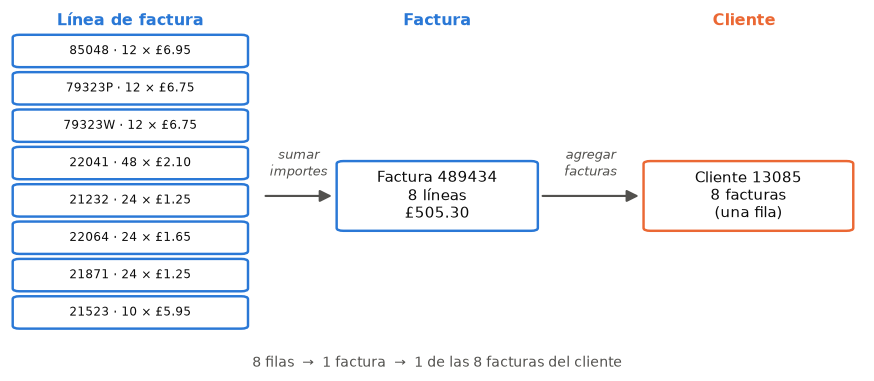

*Los tres niveles con datos reales: las líneas de la factura 489434 se
agregan en una factura, y las facturas del cliente 13085, en una sola fila
de cliente.*

Carguemos los datos. Online Retail II recoge las ventas de este comercio
entre diciembre de 2009 y diciembre de 2011; las columnas se han renombrado
a minúsculas en inglés al convertir el Excel original a parquet.

In [14]:
df = pd.read_parquet("online_retail_ii.parquet")
print(df.shape)
df.head()

(1067371, 8)


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


Cada fila es una **línea de factura**: la factura `489434` tiene varias
líneas, una por producto. Las columnas son: número de factura (`invoice`),
código y descripción del producto (`stock_code`, `description`), unidades
(`quantity`), fecha y hora (`invoice_date`), precio *unitario* en libras
(`price`), identificador de cliente (`customer_id`) y país (`country`).

¿Cuánto supone una línea? Su importe es la cantidad por el precio unitario:

In [15]:
# iloc[0] toma la fila que está en la posición 0: la primera de la tabla.
primera_linea = df.iloc[0]
importe_linea = round(primera_linea["quantity"] * primera_linea["price"], 2)
print(f"{primera_linea['quantity']} unidades × {primera_linea['price']} libras = {importe_linea} libras")

12 unidades × 6.95 libras = 83.4 libras


La primera línea supone 12 × 6,95 = 83,40 libras, no 6,95. De aquí salen los
dos errores de granularidad más frecuentes:

1. **Sumar precios en lugar de importes.** El importe de una línea es
   `quantity * price`; sumar la columna `price` no significa nada.
2. **Contar líneas en lugar de facturas.** Una factura con 8 líneas es *una*
   compra. Si medimos la frecuencia de un cliente contando líneas, quien
   compra 30 productos distintos una sola vez parecerá más frecuente que
   quien compra un producto cada semana. La frecuencia se mide con facturas
   distintas (`nunique`), no con filas.

**Datos explícitos e implícitos.** Los *explícitos* los declara el cliente
(nombre, país, una valoración); los *implícitos* se deducen de lo que hace
(qué compra, cuándo, cuánto, qué devuelve). Aquí casi todo es implícito: solo
el país procede probablemente de un dato declarado. Los implícitos hay que
interpretarlos con cuidado: comprar un juguete no significa tener hijos.

**Perfiles estáticos y dinámicos.** Un perfil *estático* describe rasgos que
casi no cambian (país, tipo de cliente); uno *dinámico*, rasgos que cambian
con cada compra (días desde la última compra, gasto acumulado). Casi todas
las variables útiles para personalizar son dinámicas y, por eso, **un perfil
dinámico solo tiene sentido referido a una fecha** (lo verás en B5).

**Identidad.** Para tener una fila por cliente hay que saber a quién
pertenece cada evento. Conviven tres situaciones: clientes *identificados*
(el evento lleva un identificador estable), clientes *anónimos* (sabemos que
hay alguien, una cookie o una sesión, pero no quién) y eventos *sin
identificador*, que no se pueden atribuir a nadie. En estos datos hay muchas
líneas sin `customer_id`; no se pueden descartar sin medir antes cuánto
representan (lo harás en B3).

*Para saber más: capítulo de la clase 1, apartados 01.3.1 a 01.3.4.*

### Ejercicio 1 · Granularidad · completar código + interpretar

(a) Completa los recuentos de la celda: el número de líneas está hecho; las
facturas, clientes, productos y países distintos se cuentan con `nunique()`.

In [16]:
# TU CÓDIGO
n_lineas = len(df)
n_facturas = df['invoice'].nunique()  # TODO: número de facturas distintas (columna invoice)
n_clientes = df['customer_id'].nunique()  # TODO: número de clientes distintos (columna customer_id)
n_codigos = df['stock_code'].nunique()  # TODO: número de códigos de producto distintos (columna stock_code)
n_paises = df['country'].nunique()  # TODO: número de países distintos (columna country)

print(f"Líneas:    {n_lineas:>9,}")
print(f"Facturas:  {n_facturas:>9,}")
print(f"Clientes:  {n_clientes:>9,}")
print(f"Productos: {n_codigos:>9,}")
print(f"Países:    {n_paises:>9,}")

Líneas:    1,067,371
Facturas:     53,628
Clientes:      5,942
Productos:     5,305
Países:           43


(b) Sin código: una factura tiene tres líneas, 10 unidades a 2 libras, 5 a 4
libras y 1 a 30 libras. ¿Cuál es su importe? ¿Qué número obtendrías si
sumaras la columna de precios?

**Tu respuesta:**

(c) La primera línea de la celda crea la columna `amount`, el importe de
cada línea; desde aquí existe para el resto del notebook. Completa la suma
de `amount` y la suma de `price` en la factura 489434 y compáralas.

In [17]:
# TU CÓDIGO
df["amount"] = df["quantity"] * df["price"]   # importe de cada línea

factura = df[df["invoice"] == "489434"]
suma_amount = factura["amount"].sum()  # TODO: suma de la columna amount de la factura
suma_price = factura["price"].sum()  # TODO: suma de la columna price de la factura
print(f"Líneas de la factura: {len(factura)}")
print(f"Suma de amount: {suma_amount:,.2f} libras")
print(f"Suma de price:  {suma_price:,.2f} libras")

Líneas de la factura: 8
Suma de amount: 505.30 libras
Suma de price:  32.65 libras


In [18]:
# Comprobación
assert (n_lineas, n_facturas, n_clientes, n_codigos, n_paises) == (1_067_371, 53_628, 5_942, 5_305, 43), \
    "Revisa los recuentos: cada uno es el nunique() de una columna."
assert round(suma_amount, 2) == 505.30, "La suma de amount de la factura 489434 debe dar 505,30 libras."
assert round(suma_price, 2) == 32.65, "Revisa la suma de price: es la suma de la columna price de la factura."
print("✔ Correcto")

✔ Correcto


Pregunta: si un informe de ventas sumara `price` en lugar de `amount`, ¿a qué clientes infravaloraría más? Usa las cifras de la factura 489434.

**Tu respuesta:**

### B2. Auditoría de calidad

Antes de construir ninguna variable hay que **auditar** el dataset: los
datos de ventas llegan con duplicados, huecos, anulaciones y registros que no
son lo que parecen, y cualquier análisis posterior hereda esos problemas.
Una auditoría básica de datos transaccionales revisa siempre lo mismo:

| Comprobación | Pregunta | Por qué importa |
| --- | --- | --- |
| Tipos | ¿Cada columna tiene el tipo correcto (fecha, número, texto)? | Un identificador leído como número puede perder ceros a la izquierda; una fecha leída como texto no se puede restar |
| Duplicados | ¿Hay filas repetidas exactamente? | Inflan importes y frecuencias |
| Nulos | ¿Qué columnas tienen valores vacíos y cuántos? | Un nulo en el identificador impide atribuir el evento |
| Cancelaciones | ¿Cómo se registran las anulaciones y devoluciones? | Si se suman como ventas, el gasto sale mal |
| Valores imposibles | ¿Hay cantidades o precios negativos o nulos fuera de las cancelaciones? | Suelen ser ajustes internos, no compras |
| Registros que no son lo que parecen | ¿Hay filas que no son productos (portes, comisiones, pruebas)? | Distorsionan el catálogo y el gasto |
| Cobertura | ¿Qué parte de los eventos y del importe tiene identificador? | Dice qué parte del negocio queda fuera del análisis |

**Ejemplo resuelto: tipos y tres filas de la auditoría.** Empezamos por los
tipos de cada columna:

In [19]:
df.dtypes

invoice                    str
stock_code                 str
description                str
quantity                 int64
invoice_date    datetime64[us]
price                  float64
customer_id              Int64
country                    str
amount                 float64
dtype: object

Son razonables: `invoice` y `stock_code` son texto (algunas facturas empiezan
por letra), la fecha es una fecha y `customer_id` es un entero que admite
nulos (`Int64`, con mayúscula). Según tu versión de pandas, el texto aparece
como `str` o como `object`: significan lo mismo. La última columna, `amount`,
es la que creaste en el ejercicio 1.

Ahora, tres comprobaciones en una tabla. `df.duplicated()` es una máscara que
vale `True` en cada fila idéntica a otra anterior:

In [20]:
auditoria_ejemplo = pd.Series({
    "Líneas duplicadas exactas": df.duplicated().sum(),
    "Líneas sin customer_id": df["customer_id"].isna().sum(),
    "Líneas sin descripción": df["description"].isna().sum(),
}, name="líneas")
tabla_ejemplo = auditoria_ejemplo.to_frame()
tabla_ejemplo["pct"] = 100 * tabla_ejemplo["líneas"] / len(df)
tabla_ejemplo

,líneas,pct
Líneas duplicadas exactas,34335,3.22
Líneas sin customer_id,243007,22.77
Líneas sin descripción,4382,0.41


Cómo se lee cada fila y qué se hace con ella:

- **34 335 líneas duplicadas exactas (3,2 %).** Misma factura, producto,
  cantidad, precio, fecha y cliente, al mismo segundo: con mucha
  probabilidad, una fila repetida al exportar. Decisión: eliminarlas y
  dejarlo documentado.
- **243 007 líneas sin `customer_id` (22,8 %).** Es el problema de identidad
  de B1: no son un error, pero no se pueden atribuir a nadie. Decisión: medir
  qué parte del negocio representan antes de excluirlas (B3).
- **4 382 líneas sin descripción (0,4 %).** Todas tienen precio 0 y ningún
  cliente: son ajustes de inventario, no ventas. Decisión: no cuentan como
  ventas.

**Registros que no son lo que parecen.** Algunas líneas tienen forma de
venta, pero no lo son. Las **cancelaciones** son facturas cuyo número empieza
por `C`, con cantidad negativa: anulaciones o devoluciones del cliente.

In [21]:
df[df["invoice"].str.startswith("C")].head(3)

,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,amount
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321,Australia,-35.40
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321,Australia,-9.90
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321,Australia,-17.00


También hay líneas con cantidades negativas que no son cancelaciones, precios
0 y **códigos que no son productos**. Los códigos de producto normales
empiezan por cinco dígitos; mira estos seis:

In [22]:
ejemplos_codigos = ["POST", "M", "DOT", "DCGS0058", "DCGS0003", "gift_0001_20"]
(df[df["stock_code"].isin(ejemplos_codigos)]
   .groupby("stock_code")
   .agg(lineas=("invoice", "size"), descripcion=("description", "first")))

,lineas,descripcion
stock_code,,
DCGS0003,14,BOXED GLASS ASHTRAY
DCGS0058,31,MISO PRETTY GUM
DOT,1446,DOTCOM POSTAGE
M,1421,Manual
POST,2122,POSTAGE
gift_0001_20,29,Dotcomgiftshop Gift Voucher £20.00


`POST` y `DOT` son gastos de envío y `M`, ajustes manuales: no son compras de
producto y, si se quedaran, el importe de los portes contaría como gasto del
cliente y "POSTAGE" aparecería entre los productos más vendidos. Pero
`DCGS0058` ("MISO PRETTY GUM") y `DCGS0003` ("BOXED GLASS ASHTRAY") son
artículos concretos, y `gift_0001_20` es una tarjeta regalo: **sí** son
productos, aunque su código no empiece por un dígito. Por eso una regla
automática ("todo lo que no empiece por dígito fuera") no basta: la lista de
códigos que se excluyen es una **decisión con criterio**, código a código.

*Para saber más: capítulo de la clase 1, apartados 01.4.1 y 01.4.2.*

### Ejercicio 2 · Checklist de auditoría · completar código + interpretar

Las tres primeras filas de la tabla son las del ejemplo. Completa las
cuatro siguientes (cancelaciones, cantidad ≤ 0 fuera de cancelaciones, precio
0 y precio negativo) y la columna de porcentaje. Recuerda: `~` invierte una
máscara y `&` combina dos, cada una entre paréntesis.

Pista:

```python
# Antes de decidir, mira unas cuantas filas de cada caso.
df[mascara].head()
```

In [23]:
# TU CÓDIGO
es_cancelacion = df["invoice"].str.startswith("C")
auditoria = pd.Series({
    "Líneas duplicadas exactas": df.duplicated().sum(),
    "Líneas sin customer_id": df["customer_id"].isna().sum(),
    "Líneas sin descripción": df["description"].isna().sum(),
    "Líneas de cancelación (factura 'C...')": len(df.loc[es_cancelacion]),  # TODO: cuenta las cancelaciones
    "Cantidad <= 0 fuera de cancelaciones": len(df[(df["quantity"]<=0) & ~es_cancelacion]),  # TODO: cantidad no positiva y no cancelación
    "Precio igual a 0": len(df[df["price"] == 0]),  # TODO: líneas con precio 0
    "Precio negativo": len(df[df["price"] < 0]),  # TODO: líneas con precio negativo
}, name="líneas")
tabla_auditoria = auditoria.to_frame()
tabla_auditoria["pct"] = 100 * tabla_auditoria['líneas'] / len(df)  # TODO: porcentaje sobre el total de líneas
tabla_auditoria

,líneas,pct
Líneas duplicadas exactas,34335,3.22
Líneas sin customer_id,243007,22.77
Líneas sin descripción,4382,0.41
Líneas de cancelación (factura 'C...'),19494,1.83
Cantidad <= 0 fuera de cancelaciones,3457,0.32
Precio igual a 0,6202,0.58
Precio negativo,5,0.00


In [24]:
# Comprobación
assert list(auditoria) == [34_335, 243_007, 4_382, 19_494, 3_457, 6_202, 5], \
    "Algún recuento no coincide: revisa la máscara de la fila que difiere."
assert round(tabla_auditoria["pct"].iloc[0], 2) == 3.22, "El porcentaje es 100 * líneas / total de líneas."
print("✔ Correcto")

✔ Correcto


Pregunta: elige tres de las filas que has completado tú (cancelaciones, cantidad ≤ 0, precio 0, precio negativo). Para cada una, di qué porcentaje de las líneas representa, si es un error o información y qué harías con ella (eliminar, guardar aparte, cuantificar).

**Tu respuesta:**

### Ejercicio 3 · Códigos que no son producto · interpretar

La celda muestra los códigos que no empiezan por un dígito, con su número de
líneas y la descripción de su primera línea. Busca un código `DCGS...` o
`gift_...` distinto de los tres de la explicación (`DCGS0058`, `DCGS0003` y
`gift_0001_20`) y explica por qué es un producto. Después, busca un código
fuera de los diez primeros del listado que sí excluirías, y di por qué.

In [25]:
# r"^\d" es una expresión regular: "empieza (^) por un dígito (\d)".
no_empieza_por_digito = ~df["stock_code"].str.match(r"^\d")
codigos_raros = (df[no_empieza_por_digito]
                 .groupby("stock_code")
                 .agg(lineas=("invoice", "size"), descripcion=("description", "first"))
                 .sort_values("lineas", ascending=False))
print(len(codigos_raros), "códigos que no empiezan por dígito")

# Muestra todas las filas sin cortar el listado.
with pd.option_context("display.max_rows", 100):
    display(codigos_raros)   # display() muestra la tabla aunque no sea la última línea de la celda

62 códigos que no empiezan por dígito


,lineas,descripcion
stock_code,,
POST,2122,POSTAGE
DOT,1446,DOTCOM POSTAGE
M,1421,Manual
C2,282,CARRIAGE
D,177,Discount
S,104,SAMPLES
BANK CHARGES,102,Bank Charges
ADJUST,67,Adjustment by john on 26/01/2010 16
AMAZONFEE,43,AMAZON FEE


**Tu respuesta:**

### B3. Limpieza y cobertura

**La cobertura del identificador.** ¿Cuánto del negocio perdemos si
trabajamos solo con clientes identificados? Depende de cómo lo midamos, y
hay tres unidades posibles:

- en **líneas**: qué parte de las líneas de venta no tiene cliente;
- en **facturas**: qué parte de las compras no tiene cliente;
- en **importe**: qué parte de la facturación no tiene cliente.

Las tres responden a la misma pregunta y pueden dar cifras muy distintas.
Ejemplo resuelto: la cobertura **antes** de limpiar, sobre las ventas en
bruto (facturas sin `C`, cantidad y precio positivos). La celda vuelve a
crear `amount`, por si no has hecho el ejercicio 1, y su propia máscara de
cancelación:

In [26]:
df["amount"] = df["quantity"] * df["price"]
es_cancelacion_bruta = df["invoice"].str.startswith("C")
ventas_brutas = df[~es_cancelacion_bruta & (df["quantity"] > 0) & (df["price"] > 0)]
sin_cliente = ventas_brutas["customer_id"].isna()

print(f"Líneas de venta sin cliente:  {sin_cliente.mean():.1%}")   # la media de True/False es la proporción
print(f"Importe de venta sin cliente: "
      f"{ventas_brutas.loc[sin_cliente, 'amount'].sum() / ventas_brutas['amount'].sum():.1%}")
print(f"Facturas de venta sin cliente: "
      f"{ventas_brutas.loc[sin_cliente, 'invoice'].nunique() / ventas_brutas['invoice'].nunique():.1%}")

Líneas de venta sin cliente:  22.7%
Importe de venta sin cliente: 15.4%
Facturas de venta sin cliente: 7.8%


Tres cifras para la misma pregunta: el 22,7 % de las líneas de venta, el
15,4 % del importe y el 7,8 % de las facturas. Si informáramos solo de una,
la elección cambiaría el mensaje. Además, son una **primera estimación**:
todavía incluyen las líneas duplicadas y los portes, comisiones y ajustes
que vamos a quitar. La cifra que acompañará a la tabla de cliente se calcula
después de limpiar (ejercicio 4).

**Las reglas de limpieza.** Con la auditoría hecha, fijamos las reglas. Cada
una es una decisión con su motivo:

| Regla | Decisión | Motivo |
| --- | --- | --- |
| Duplicados exactos | Eliminar | Duplicados técnicos probables; inflarían el gasto |
| Códigos que no son producto | Eliminar (lista explícita) | Portes, comisiones y ajustes no son compras |
| Líneas sin `customer_id` | Excluir de la tabla de cliente; cuantificar | No se pueden atribuir; hay que medir qué parte del importe representan |
| Ventas | Factura sin `C`, cantidad > 0, precio > 0 | Define qué es una compra |
| Cancelaciones (`C...`) | Guardar aparte como devoluciones | Son información del cliente, no ruido |
| Precio 0 o negativo, cantidad ≤ 0 sin `C` | Excluir | Ajustes internos o líneas sin importe; no son compras |

**De un error de datos a un error de negocio.** Los problemas de calidad no
se quedan en la tabla; viajan hasta las decisiones:

- duplicados sin eliminar → el gasto de algunos clientes sale inflado →
  entran en el programa VIP clientes que no lo merecen;
- cancelaciones sumadas como ventas → un cliente que compra y devuelve todo
  parece un gran cliente;
- portes contados como producto → "POSTAGE" sale como producto estrella y un
  recomendador de "lo más vendido" lo sugiere a todo el mundo;
- líneas sin cliente descartadas en silencio → el informe dice "nuestros
  clientes gastan X" sin avisar de la parte de la facturación que falta.

Cualquier modelo posterior, por sofisticado que sea, hereda estos errores.

**La lista de códigos que no son producto.** Es una decisión escrita, con un
motivo por código, y es la que usaremos en adelante para que todas las
clases partan de las mismas reglas. Ejecuta la celda:

In [27]:
CODIGOS_NO_PRODUCTO = {
    "POST", "DOT", "C2",               # portes: POSTAGE, DOTCOM POSTAGE, CARRIAGE
    "M", "m",                          # ajustes manuales (Manual)
    "D",                               # descuentos (Discount)
    "S",                               # muestras (SAMPLES)
    "BANK CHARGES", "AMAZONFEE",       # comisiones bancarias y de Amazon
    "CRUK",                            # comisión de Cancer Research UK
    "ADJUST", "ADJUST2", "B",          # ajustes contables (Adjustment, Adjust bad debt)
    "C3",                              # sin descripción, precio 0
    "PADS",                            # relleno de cojines con precios de 0 a 36,60
    "TEST001", "TEST002",              # productos de prueba
}
print(len(CODIGOS_NO_PRODUCTO), "códigos excluidos")

17 códigos excluidos


`PADS` es el caso más discutible: se excluye porque sus precios no parecen
ventas reales, pero otra persona podría decidir lo contrario (lo explora la
ampliación X1). Lo importante es que la decisión queda escrita.

*Para saber más: capítulo de la clase 1, apartados 01.4.3 a 01.4.5.*

### Ejercicio 4 · Limpieza y cobertura · completar código + interpretar

(a) Aplica las reglas paso a paso, dejando cada resultado en una variable
con nombre: `sin_duplicados`, `solo_productos`, `lineas` (las que tienen
cliente), `sales` (ventas) y `returns` (devoluciones). La conversión del tipo
de `customer_id` y la máscara de cancelación sobre las líneas limpias están
hechas.

Pistas:

```python
# tabla.drop_duplicates() devuelve la tabla sin las filas repetidas exactas.
# ~tabla["col"].isin(LISTA) es True en las filas cuyo valor NO está en la lista.
# .notna() es True donde hay valor (lo contrario de .isna()).
```

In [28]:
# TU CÓDIGO
sin_duplicados = df.drop_duplicates()  # TODO: quita las líneas duplicadas exactas
solo_productos = sin_duplicados[~sin_duplicados["stock_code"].isin(CODIGOS_NO_PRODUCTO)]  # TODO: quita los códigos de la lista
lineas = solo_productos[solo_productos["customer_id"].notna()]  # TODO: quédate con las líneas que tienen cliente
# Int64 admite nulos; como ya no quedan, pasamos al entero normal (int64).
lineas = lineas.astype({"customer_id": "int64"})
# La máscara de cancelación se recalcula sobre las líneas ya limpias.
es_cancelacion_limpia = lineas["invoice"].str.startswith("C")

sales = lineas[(~es_cancelacion_limpia) & (lineas["amount"] > 0) & (lineas["price"] > 0)]  # TODO: ventas (sin C, cantidad y precio positivos)
returns = lineas[es_cancelacion_limpia]  # TODO: devoluciones (facturas C)

print(f"Líneas de partida:             {len(df):>9,}")
print(f"Líneas de venta identificadas: {len(sales):>9,}")
print(f"Líneas de devolución:          {len(returns):>9,}")

Líneas de partida:             1,067,371
Líneas de venta identificadas:   776,579
Líneas de devolución:             17,586


In [29]:
# Comprobación
assert len(sales) == 776_579, "Revisa las reglas: duplicados, códigos, cliente y la definición de venta."
assert len(returns) == 17_586, "Las devoluciones son las líneas de `lineas` cuya factura empieza por C."
print("✔ Correcto")

✔ Correcto


(b) Calcula la parte sin cliente en líneas, importe y facturas sobre las
ventas de `solo_productos`: ya sin duplicados ni códigos que no son
producto, pero **todavía con** las líneas sin cliente. La máscara de ventas
(`es_venta`, la regla "Ventas" de la tabla de B3) está hecha; usa como modelo
la celda de cobertura de la explicación de B3.

In [30]:
es_venta = (~solo_productos["invoice"].str.startswith("C")
            & (solo_productos["quantity"] > 0) & (solo_productos["price"] > 0))
todas_las_ventas = solo_productos[es_venta]

In [31]:
# TU CÓDIGO
sin_cliente_final = todas_las_ventas["customer_id"].isna()  # TODO: True si la línea no tiene cliente
pct_lineas = sin_cliente.mean()  # TODO: proporción de líneas sin cliente
pct_importe = (sin_cliente_final.isin(todas_las_ventas).sum() / todas_las_ventas["amount"].sum()) # TODO: proporción del importe (amount)
pct_facturas = sin_cliente_final.isin(todas_las_ventas).sum() / todas_las_ventas["invoice"].sum()  # TODO: proporción de facturas (invoice)

print(f"Líneas de venta sin cliente:   {pct_lineas:.1%}")
print(f"Importe de venta sin cliente:  {pct_importe:.1%}")
print(f"Facturas de venta sin cliente: {pct_facturas:.1%}")

TypeError: ufunc 'divide' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

In [ ]:
# Comprobación
assert round(pct_importe, 3) != 0, "Si te sale 0 %, has calculado sobre `sales`, que ya no tiene líneas sin cliente."
assert round(pct_importe, 3) == 0.131, "Calcula el importe sobre `todas_las_ventas` (las ventas de solo_productos)."
assert (round(pct_lineas, 3), round(pct_facturas, 3)) == (0.226, 0.074), "Revisa los porcentajes de líneas y facturas."
print("✔ Correcto")

(c) Preguntas: (i) ¿por qué el porcentaje sin cliente es tan distinto en
líneas, facturas e importe? (ii) ¿Cuál comunicarías a marketing y qué frase
acompañaría siempre a la tabla de cliente?

**Tu respuesta:**

### B4. SQL y pandas a escala

Si te has atascado en el ejercicio 4 o te lo has saltado, activa la celda de
rescate: carga las ventas (`sales`) y devoluciones (`returns`) ya limpias.

In [ ]:
# Celda de rescate: cambia False por True solo si no has llegado hasta aquí.
USAR_RESCATE = False
if USAR_RESCATE:
    limpias = pd.read_parquet("lineas_limpias.parquet")
    sales = limpias[~limpias["is_return"]]
    returns = limpias[limpias["is_return"]]
    print("Rescate cargado: ventas y devoluciones de lineas_limpias.parquet")

En la demo viste que SQL y pandas dan la misma tabla con 21 líneas. Estas
son las equivalencias que necesitas:

| Operación | SQL | pandas |
| --- | --- | --- |
| Elegir columnas | `SELECT a, b` | `df[["a", "b"]]` |
| Filtrar filas | `WHERE quantity > 0` | `df[df["quantity"] > 0]` (una máscara) |
| Agregar por grupo | `GROUP BY customer_id` + `COUNT`, `SUM`, `MAX` | `df.groupby("customer_id").agg(...)` |
| Contar distintos | `COUNT(DISTINCT invoice)` | `("invoice", "nunique")` |
| Unir tablas | `JOIN products ON ...` | `df.merge(products, on=...)` |
| Ordenar y limitar | `ORDER BY n DESC LIMIT 5` | `.sort_values(ascending=False).head(5)` |

¿Cuándo usar cada uno? No compiten. **SQL** es la herramienta natural para
consultar los datos en su origen: filtra y agrega dentro de la base de datos
y solo trae a tu ordenador el resultado, que puede ser mucho más pequeño.
**pandas** es la herramienta natural para seguir analizando en Python:
gráficos, transformaciones, modelos. Un flujo habitual es extraer con SQL
una tabla razonable y continuar con pandas.

**Ejemplo resuelto: `JOIN` y `merge`.** Muchas veces la información está
repartida en dos tablas: las ventas tienen el código del producto y la
descripción está en una tabla de productos. Unirlas por la columna común es
un `JOIN` en SQL y un `merge` en pandas. Con dos tablas de juguete, en su
propia base de datos (`con_join`):

In [ ]:
ventas_join = pd.DataFrame({
    "customer_id": [12346, 12347, 12347, 12349, 12349],
    "stock_code":  ["85123A", "85123A", "22423", "22423", "84879"],
    "quantity":    [6, 12, 2, 4, 8],
})
productos_join = pd.DataFrame({
    "stock_code":  ["85123A", "22423", "84879"],
    "description": ["WHITE HANGING HEART T-LIGHT HOLDER", "REGENCY CAKESTAND 3 TIER",
                    "ASSORTED COLOUR BIRD ORNAMENT"],
})

con_join = sqlite3.connect(":memory:")
ventas_join.to_sql("ventas", con_join, index=False)
productos_join.to_sql("productos", con_join, index=False)

# v y p son alias: nombres cortos para las dos tablas. ON dice qué columna las une.
consulta_join = """
SELECT v.stock_code,
       p.description,
       COUNT(DISTINCT v.customer_id) AS n_customers,
       SUM(v.quantity)               AS units
FROM ventas    AS v
JOIN productos AS p ON v.stock_code = p.stock_code
GROUP BY v.stock_code, p.description
ORDER BY v.stock_code
"""
join_sql = pd.read_sql(consulta_join, con_join).set_index("stock_code")
join_sql

In [ ]:
# merge une las dos tablas por stock_code: cada venta recibe la descripción de su producto.
ventas_con_descripcion = ventas_join.merge(productos_join, on="stock_code")
join_pandas = (ventas_con_descripcion
               .groupby(["stock_code", "description"])
               .agg(n_customers=("customer_id", "nunique"), units=("quantity", "sum"))
               .reset_index("description"))   # description vuelve a ser una columna, como en SQL

pd.testing.assert_frame_equal(join_sql, join_pandas, check_dtype=False)
print("JOIN y merge dan la misma tabla")
join_pandas

`85123A` lo compran 2 clientes distintos (18 unidades), `22423` también 2 (6
unidades) y `84879`, uno (8 unidades). Las dos versiones coinciden. En el
ejercicio 5 harás lo mismo a escala, con las 776 579 líneas de venta.

*Para saber más: capítulo de la clase 1, apartado 01.5.4.*

### Ejercicio 5 · SQL y pandas a escala · escribir código + interpretar

La celda modelo carga las ventas en una base de datos SQLite nueva
(`con_lab`, para no mezclarla con la de la demo) y construye la **tabla de
facturas** (una fila por factura) con SQL y con pandas. Léela: es el patrón
que vas a seguir.

In [ ]:
con_lab = sqlite3.connect(":memory:")
ventas_sql = sales[["invoice", "customer_id", "invoice_date", "stock_code",
                    "description", "quantity", "price", "amount"]].copy()
ventas_sql["invoice_date"] = ventas_sql["invoice_date"].astype(str)
ventas_sql.to_sql("sales", con_lab, index=False)

consulta_facturas = """
SELECT invoice,
       customer_id,
       MIN(invoice_date)     AS invoice_date,
       COUNT(*)              AS n_lines,
       SUM(quantity * price) AS amount
FROM sales
GROUP BY invoice
ORDER BY invoice
"""
facturas_sql = pd.read_sql(consulta_facturas, con_lab).set_index("invoice")
# SQLite devuelve la fecha como texto: la pasamos por pd.to_datetime antes de comparar con pandas.
facturas_sql["invoice_date"] = pd.to_datetime(facturas_sql["invoice_date"])

facturas_pandas = sales.groupby("invoice").agg(
    customer_id=("customer_id", "first"),
    invoice_date=("invoice_date", "min"),
    n_lines=("invoice", "size"),
    amount=("amount", "sum"),
)
pd.testing.assert_frame_equal(facturas_sql, facturas_pandas, check_dtype=False)
print(f"{len(facturas_sql):,} facturas: SQL y pandas coinciden")
facturas_sql.head()

Ahora tú: escribe la **tabla de cliente RFM** (`frequency`, `monetary` y
`recency_days` a 2011-12-10) con SQL y con pandas. Sigue la consulta y el
código de pandas de la demo (parte A.4), con estas diferencias:

- la consulta va contra `con_lab` (la tabla también se llama `sales`);
- sin redondear: ni `ROUND` en SQL ni `.round(2)` en pandas, porque aquí
  comparamos los importes exactos;
- guarda el resultado de SQL en `rfm_sql` y el de pandas en `rfm_pandas`,
  los dos con `customer_id` como índice y las tres columnas en el orden
  `frequency`, `monetary`, `recency_days` (quita `last_purchase`, como en la
  demo).

La tabla de productos, con su `JOIN`, está en la ampliación X1.

In [ ]:
# TU CÓDIGO
# 1. Escribe la consulta: agrupa por cliente y calcula frequency, monetary y recency_days.
# 2. Léela con pd.read_sql y usa customer_id como índice.
# 3. La misma tabla con groupby().agg(), la recencia y sin last_purchase.
# 4. Mira las primeras filas; la celda de comprobación compara las dos tablas.

Si la comparación falla, el mensaje (en inglés) indica la columna que difiere, por ejemplo `column name="monetary"`: empieza a revisar por esa.

In [ ]:
# Comprobación
assert len(rfm_sql) == 5_852, "Debe haber una fila por cliente: 5 852. ¿Has consultado con_lab?"
pd.testing.assert_frame_equal(rfm_sql, rfm_pandas, check_dtype=False)
print("✔ Correcto")

Pregunta: con las cifras de este ejercicio, ¿cuántas filas viajarían de la base de datos a Python si agregas en SQL y cuántas si agregas en pandas? Propón un caso concreto en el que, aun así, preferirías hacer la agregación en pandas.

**Tu respuesta:**

### B5. El perfil de cliente

Si te has atascado antes, activa la celda de rescate: carga `sales` y
`returns` ya limpias.

In [ ]:
# Celda de rescate: cambia False por True solo si no has llegado hasta aquí.
USAR_RESCATE = False
if USAR_RESCATE:
    limpias = pd.read_parquet("lineas_limpias.parquet")
    sales = limpias[~limpias["is_return"]]
    returns = limpias[limpias["is_return"]]
    print("Rescate cargado: ventas y devoluciones de lineas_limpias.parquet")

**La fecha de referencia: toda variable es "a fecha de".** ¿Cuál es la
recencia de Ana, la clienta de las seis facturas de la parte A? La pregunta
no tiene respuesta hasta que decimos *a qué fecha*. Volvemos a crear las
seis facturas en esta celda:

In [ ]:
facturas_ejemplo = pd.DataFrame({
    "invoice":     ["F1", "F2", "F3", "C4", "F5", "F6"],
    "customer_id": ["Ana", "Ana", "Bruno", "Ana", None, "Carla"],
    "date": pd.to_datetime(["2011-11-02", "2011-11-28", "2011-10-15",
                            "2011-11-30", "2011-12-05", "2011-06-01"]),
    "amount":      [60.0, 40.0, 250.0, -20.0, 35.0, 30.0],
})
ventas_ejemplo = facturas_ejemplo[~facturas_ejemplo["invoice"].str.startswith("C")
                                  & facturas_ejemplo["customer_id"].notna()]
rfm_ejemplo = ventas_ejemplo.groupby("customer_id").agg(last_purchase=("date", "max"))

for fecha in ["2011-12-10", "2012-03-10"]:
    dias = (pd.Timestamp(fecha) - rfm_ejemplo.loc["Ana", "last_purchase"]).days
    print(f"Recencia de Ana a {fecha}: {dias} días")

El mismo cliente, con el mismo historial, tiene recencia 12 o 103 según el
día en que miremos. Ninguna está mal; lo que estaría mal es no decir cuál
usamos. Por eso toda tabla de cliente se construye a una **fecha de
referencia** explícita (en inglés, *snapshot date*), que se guarda junto con
la tabla. Aquí es `FECHA_REFERENCIA`, el 10 de diciembre de 2011, el día
siguiente a la última factura. Calcular la recencia con "hoy"
(`pd.Timestamp.today()`) es un error: el resultado cambia cada vez que se
ejecuta y, en datos que terminan en 2011, todos los clientes tendrían más de
catorce años de recencia.

La fecha de referencia también decide **qué datos se pueden usar: solo los
anteriores a ella**. Mira qué pasa si calculamos la recencia de Ana a 15 de
noviembre de 2011 con y sin ese filtro:

In [ ]:
corte_ejemplo = pd.Timestamp("2011-11-15")
ventas_ana = ventas_ejemplo[ventas_ejemplo["customer_id"] == "Ana"]
ventas_ana_antes = ventas_ana[ventas_ana["date"] < corte_ejemplo]   # solo las anteriores al corte

for nombre, tabla in [("con filtro", ventas_ana_antes), ("sin filtro", ventas_ana)]:
    recencia = (corte_ejemplo - tabla["date"].max()).days
    print(f"Ana a {corte_ejemplo.date()}, {nombre}: recencia {recencia} días, "
          f"frecuencia {tabla['invoice'].nunique()}")

Con el filtro, a 15 de noviembre Ana llevaba 13 días sin comprar y tenía una
sola compra. Sin el filtro, la tabla "sabe" que compraría el 28 de
noviembre: recencia −13 días (imposible) y una compra de más. Usar datos
posteriores a la fecha de referencia es hacer trampa; en la clase 6 este
error tendrá nombre: *fuga de información*.

**Las variables de la tabla y sus decisiones de diseño.** RFM es un buen
comienzo, pero la tabla de cliente incluye algo más:

- **`avg_ticket`** = `monetary / frequency`: el tamaño típico de una compra.
- **`tenure_days`**: días desde la primera compra hasta la fecha de
  referencia. Es antigüedad *observada*: los datos empiezan el 1 de
  diciembre de 2009, y quien ya compraba entonces pudo empezar mucho antes
  (esta limitación se llama *censura*).
- **Devoluciones, en positivo y por separado.** Las devoluciones se agregan
  por cliente igual que las compras (`n_return_invoices`, `return_amount`).
  En las cancelaciones la cantidad es negativa y, por tanto, el importe
  también: se cambia de signo para guardar el importe devuelto en positivo.
- **¿Neto o bruto?** `monetary` es el gasto *bruto*, sin restar
  devoluciones. Restarlas daría una cifra más cercana a lo que el cliente
  aporta, pero mezclaría dos comportamientos (comprar y devolver). Guardarlos
  por separado permite calcular el neto cuando haga falta y, a la vez,
  estudiar las devoluciones como señal.
- **País más frecuente.** Un cliente puede comprar desde más de un país; nos
  quedamos con el de más líneas de compra.
- **`return_share`** = `return_amount / monetary`: la proporción devuelta.
  Puede superar 1 si el cliente devuelve en el periodo algo comprado antes de
  diciembre de 2009, otra cara de la censura.
- **¿Qué es una compra?** Una factura, no una línea ni un día.

**Ejemplo resuelto: el cliente 12346.** Para ver por qué importa separar
ventas y devoluciones, miramos todas sus facturas. `pd.concat` apila dos
tablas, una debajo de otra:

In [ ]:
todas_las_lineas = pd.concat([sales, returns])
lineas_12346 = todas_las_lineas[todas_las_lineas["customer_id"] == 12346]
(lineas_12346.groupby("invoice")
             .agg(date=("invoice_date", "min"), units=("quantity", "sum"), amount=("amount", "sum"))
             .sort_values("date"))

El 18 de enero de 2011 compra 74 215 unidades de un mismo producto por
77 183,60 libras y dieciséis minutos después la factura se cancela entera
(`C541433`). Casi con seguridad es un error de pedido. Con `monetary` bruto,
este cliente tendría un gasto de más de 77 000 libras y parecería uno de los
mejores del comercio. Con `return_amount` y `return_share` la tabla lo
delata: devuelve prácticamente todo lo que compra.

**¿Cuántos clientes hay?** Hay 5 942 identificadores en bruto, pero la tabla
tendrá 5 852 clientes con al menos una compra de producto: 66
identificadores solo tenían portes, comisiones, ajustes o productos de
prueba; 23 solo tenían devoluciones (de compras anteriores al periodo); y 1
tenía una única línea a precio 0. La respuesta a "¿cuántos clientes
tenemos?" depende de la definición; usamos 5 852 porque son los únicos para
los que recencia, frecuencia y gasto tienen sentido. Seguir cada salto con
código es la ampliación X2.

**La tabla analítica de cliente.** El resultado de esta parte es una fila
por cliente, con `customer_id` como índice y estas 11 columnas, en este
orden, todas a fecha 2011-12-10:

| Variable | Definición | Qué captura |
| --- | --- | --- |
| `country` | País más frecuente en sus compras | Mercado |
| `recency_days` | Días entre la última compra y la fecha de referencia | Actividad reciente |
| `frequency` | Número de facturas de venta distintas | Hábito de compra |
| `monetary` | Suma de `quantity * price` de las ventas (bruto) | Volumen de negocio |
| `avg_ticket` | `monetary / frequency` | Tamaño típico de una compra |
| `n_products` | Número de productos distintos comprados | Amplitud de la relación |
| `tenure_days` | Días entre la primera compra y la fecha de referencia | Antigüedad observada |
| `n_return_invoices` | Número de facturas de cancelación | Frecuencia de devoluciones |
| `return_amount` | Importe devuelto (en positivo) | Volumen devuelto |
| `has_returns` | Si ha devuelto algo alguna vez | Indicador simple |
| `return_share` | `return_amount / monetary` | Proporción devuelta |

*Para saber más: capítulo de la clase 1, apartados 01.5.2, 01.5.3 y 01.5.7.*

### Ejercicio 6 · La tabla de cliente · completar código + interpretar

(a) Completa la agregación de las variables de compra y las tres derivadas.
La primera línea del `agg` está hecha y te sirve de modelo. Para las fechas
usa la columna `day` (la fecha sin hora, que cuenta días naturales), no
`invoice_date`. Tres de estas variables ya salieron en el ejercicio 5, pero
este ejercicio no usa nada de él.

In [ ]:
# TU CÓDIGO
dia = sales["invoice_date"].dt.normalize()
customers = (sales.assign(day=dia)            # añade la columna day sin modificar sales
                  .groupby("customer_id")
                  .agg(
                      first_purchase=("day", "min"),      # modelo: ("columna", "función")
                      last_purchase=COMPLETA,  # TODO: fecha de la última compra (columna day)
                      frequency=COMPLETA,  # TODO: facturas de venta distintas
                      monetary=COMPLETA,  # TODO: gasto bruto (columna amount)
                      n_products=COMPLETA,  # TODO: productos distintos
                  ))

customers["recency_days"] = COMPLETA  # TODO: días desde la última compra
customers["tenure_days"] = COMPLETA  # TODO: días desde la primera compra
customers["avg_ticket"] = COMPLETA  # TODO: gasto medio por factura
customers.head()

Lee la salida: cada fila es un cliente. El 12347 compró hace 3 días y
tiene 8 facturas; el 12346, con solo 3 facturas, tiene un ticket medio de más
de 25 000 libras, el pedido que verás cancelado en (b).

(b) Ejecuta y lee estas dos celdas. La primera agrega las devoluciones (con
el importe en positivo) y calcula el país más frecuente en tres pasos:
cuenta las líneas de cada par cliente–país (`size` cuenta filas por grupo y
`reset_index` las convierte en una columna `n`), ordena los países de cada
cliente de más a menos frecuente y se queda con la primera fila de cada
cliente (`drop_duplicates("customer_id")` conserva la primera aparición).

In [ ]:
devoluciones = returns.groupby("customer_id").agg(
    n_return_invoices=("invoice", "nunique"),
    return_amount=("amount", "sum"),
)
# En las cancelaciones el importe es negativo; lo guardamos en positivo.
devoluciones["return_amount"] = -devoluciones["return_amount"]

# País más frecuente: líneas de compra de cada cliente en cada país, de más a menos.
compras_por_pais = sales.groupby(["customer_id", "country"]).size().reset_index(name="n")
compras_por_pais = compras_por_pais.sort_values(["customer_id", "n"], ascending=[True, False])
pais = compras_por_pais.drop_duplicates("customer_id").set_index("customer_id")["country"]
devoluciones.head(3)

La segunda une todo. `join` une por el índice (el `customer_id`). Quien no ha
devuelto nada no aparece en `devoluciones` y recibe un nulo, que `fillna`
sustituye por 0: no haber devuelto nada es un 0, no un dato desconocido. Al
final se eligen y ordenan las 11 columnas de la tabla analítica.

In [ ]:
customers = customers.join(devoluciones)
customers = customers.fillna({"n_return_invoices": 0, "return_amount": 0.0})
customers["country"] = pais   # se alinea por customer_id (el índice), no por posición
customers["n_return_invoices"] = customers["n_return_invoices"].astype(int)
customers["has_returns"] = customers["n_return_invoices"] > 0
customers["return_share"] = customers["return_amount"] / customers["monetary"]

columnas = ["country", "recency_days", "frequency", "monetary", "avg_ticket",
            "n_products", "tenure_days", "n_return_invoices", "return_amount",
            "has_returns", "return_share"]
customers = customers[columnas]
print(customers.shape)
customers.head()

(c) Guarda tu tabla en `salidas/customers.parquet`; la comprobación la
compara con la tabla de referencia. Pista:

```python
# Guarda la tabla en la carpeta salidas/, junto al notebook.
customers.to_parquet(DIR_SALIDAS / "customers.parquet")
```

Si la comparación falla, el mensaje (en inglés) indica la columna que
difiere, por ejemplo `column name="monetary"`: empieza a revisar por esa.

In [ ]:
# TU CÓDIGO
ruta_customers = COMPLETA  # TODO: carpeta salidas/ y nombre customers.parquet
customers.to_parquet(ruta_customers)

In [ ]:
# Comprobación
referencia = pd.read_parquet("customers_referencia.parquet")
pd.testing.assert_frame_equal(customers, referencia)
assert (DIR_SALIDAS / "customers.parquet").exists(), "Guarda la tabla en salidas/customers.parquet."
print("✔ Correcto: tu tabla es idéntica a la de referencia")

Si no has llegado hasta aquí, activa esta celda de rescate: carga la tabla
de referencia como `customers` para que puedas hacer (d).

In [ ]:
# Celda de rescate: cambia False por True solo si no has completado (a), (b) y (c).
USAR_RESCATE = False
if USAR_RESCATE:
    customers = pd.read_parquet("customers_referencia.parquet")
    print("Rescate cargado: tabla de cliente de referencia,", customers.shape)

(d) La directora quiere invitar a un programa VIP a los 50 clientes con más
`monetary`. ¿Entrarían el 12346 y el 16446? ¿Qué regla añadirías a la
selección y con qué variable? Ejecuta la celda y mira sus filas.

In [ ]:
# Los 50 clientes con más gasto, de mayor a menor.
top_50 = customers.sort_values("monetary", ascending=False).head(50)
# `in` comprueba si un valor está en una colección, como con las listas de Python.
print("¿Entran 12346 y 16446?", 12346 in top_50.index, 16446 in top_50.index)
# get_loc da la posición en la tabla (se cuenta desde 0): sumamos 1 para el puesto.
print("Puesto del 12346:", top_50.index.get_loc(12346) + 1)
print("Puesto del 16446:", top_50.index.get_loc(16446) + 1)
print("Clientes del top 50 que devuelven más de la mitad:", (top_50["return_share"] > 0.5).sum())
# Con una lista de clientes, .loc muestra sus filas: compara monetary y return_amount.
top_50.loc[[12346, 16446], ["monetary", "return_amount", "return_share"]]

**Tu respuesta:**

### Ejercicio 7 · Otra fecha de referencia · completar código + interpretar

Vamos a reconstruir dos variables tal como eran el 10 de septiembre de 2011.

(a) Calcula `recency_days` y `frequency` a 2011-09-10 con las ventas
**anteriores** a esa fecha (`rfm_antes`). Pista:

```python
# Las fechas se comparan igual que los números: True si es anterior al corte.
FECHA_CORTE = pd.Timestamp("2011-09-10")
sales_antes = sales[sales["invoice_date"] < FECHA_CORTE]
# .min() da el valor más pequeño de una columna: útil para buscar valores imposibles.
```

In [ ]:
# TU CÓDIGO
FECHA_CORTE = pd.Timestamp("2011-09-10")
sales_antes = COMPLETA  # TODO: solo las ventas anteriores al corte
rfm_antes = (sales_antes.assign(day=sales_antes["invoice_date"].dt.normalize())
             .groupby("customer_id")
             .agg(
                 last_purchase=("day", "max"),
                 frequency=("invoice", "nunique"),
             ))
rfm_antes["recency_days"] = COMPLETA  # TODO: días desde la última compra hasta el corte
print(f"{len(rfm_antes):,} clientes a {FECHA_CORTE.date()}")

In [ ]:
# Comprobación de (a)
assert len(rfm_antes) == 5_256, "Con el filtro debe haber 5 256 clientes: revisa la comparación con FECHA_CORTE."
assert rfm_antes.loc[12347, ["recency_days", "frequency"]].tolist() == [39, 6], \
    "Revisa rfm_antes: la recencia se mide hasta FECHA_CORTE."
print("✔ Correcto")

(b) Repite el cálculo con **todas** las ventas, sin el filtro
(`rfm_sin_filtro`): es la celda de (a) usando `sales` en lugar de
`sales_antes`. Después, la celda siguiente compara los clientes 12347 y 14799
en las dos versiones.

In [ ]:
# TU CÓDIGO
ventas_usadas = COMPLETA  # TODO: usa todas las ventas, sin filtrar por la fecha de corte
rfm_sin_filtro = (ventas_usadas.assign(day=ventas_usadas["invoice_date"].dt.normalize())
                  .groupby("customer_id")
                  .agg(
                      last_purchase=("day", "max"),
                      frequency=("invoice", "nunique"),
                  ))
rfm_sin_filtro["recency_days"] = (FECHA_CORTE - rfm_sin_filtro["last_purchase"]).dt.days

In [ ]:
# Comprobación de (b)
assert rfm_sin_filtro.loc[12347, "frequency"] == 8, "En (b) usa todas las ventas (sales), sin el filtro."
print("✔ Correcto")

In [ ]:
# Los clientes 12347 y 14799, con filtro y sin filtro.
clientes_comparar = [12347, 14799]
comparacion = rfm_antes.loc[clientes_comparar, ["recency_days", "frequency"]].join(
    rfm_sin_filtro.loc[clientes_comparar, ["recency_days", "frequency"]],
    lsuffix="_con_filtro", rsuffix="_sin_filtro")
comparacion

Preguntas: (i) ¿qué significa que a 2011-09-10 haya menos clientes que a
2011-12-10 (5 852)? (ii) Hoy te piden reconstruir la tabla tal como era el
10 de septiembre para elegir a quién se dirigía una campaña de reactivación
de entonces (clientes que llevaban mucho tiempo sin comprar). Si usas todo el
histórico sin filtrar, ¿qué recencia y qué frecuencia tendrían el 12347 y el
14799, y en qué cambia la decisión sobre el 14799? ¿Con qué comprobación de
una línea lo detectarías?

**Tu respuesta:**

### B6. Distribuciones y *long tail*

Si te has atascado antes, activa la celda de rescate: carga `sales`,
`returns` y la tabla de cliente de referencia como `customers`.

In [ ]:
# Celda de rescate: cambia False por True solo si no has llegado hasta aquí.
USAR_RESCATE = False
if USAR_RESCATE:
    limpias = pd.read_parquet("lineas_limpias.parquet")
    sales = limpias[~limpias["is_return"]]
    returns = limpias[limpias["is_return"]]
    customers = pd.read_parquet("customers_referencia.parquet")
    print("Rescate cargado: ventas, devoluciones y tabla de cliente de referencia")

**Media frente a mediana.** Con la tabla construida, la tentación es
resumirla con medias: "nuestro cliente medio gasta X". Antes, un ejemplo
pequeño: diez clientes, nueve particulares y un mayorista.

In [ ]:
gasto = pd.Series([120, 95, 150, 80, 110, 60, 130, 90, 105, 9_000],
                  index=[f"C{i:02d}" for i in range(1, 11)], name="gasto")
print(f"Media:   £{gasto.mean():8,.1f}")
print(f"Mediana: £{gasto.median():8,.1f}")
print(f"Media sin el mayorista: £{gasto.drop('C10').mean():,.1f}")

La media dice que el cliente típico gasta casi 1 000 libras, pero ningún
cliente gasta eso: nueve gastan entre 60 y 150 y uno gasta 9 000. La
**mediana** (el valor que deja la mitad de los clientes por debajo) sí
describe al cliente típico. Cuando una distribución tiene una cola larga
hacia la derecha se dice que es **asimétrica positiva**: la media se
desplaza hacia la cola y deja de representar al centro.

**Concentración.** Otra forma de verlo: ¿qué parte del gasto total reúnen
los clientes que más gastan? Se ordena el gasto de mayor a menor, se toma el
primer 10 % de clientes y se divide su suma entre la suma total:

In [ ]:
gasto_ordenado_ejemplo = gasto.sort_values(ascending=False)
top_10_ejemplo = gasto_ordenado_ejemplo.head(int(len(gasto_ordenado_ejemplo) * 0.10))   # el 10 % de 10 clientes: 1
print("Clientes en el 10 % con más gasto:", top_10_ejemplo.index.tolist())
print(f"Su parte del gasto total: {top_10_ejemplo.sum() / gasto_ordenado_ejemplo.sum():.1%}")
print(f"Asimetría (skew) de los diez gastos: {gasto.skew():.1f}")

Un solo cliente (C10) concentra el 90,5 % del gasto. Lo formalizamos con dos
ideas:

- Los **percentiles** generalizan la mediana: el percentil 25 deja por debajo
  a la cuarta parte de los clientes, el 75 a tres cuartas partes y el 99 al
  99 %. Si el percentil 99 está muy lejos del 75, unos pocos clientes muy
  grandes tiran de la media.
- El **coeficiente de asimetría** (*skewness*, en pandas `.skew()`) vale 0
  en una distribución simétrica; como referencia orientativa, por encima de 1
  ya indica una asimetría fuerte. Los diez gastos del ejemplo, con un único
  mayorista, ya dan un valor muy alto.

Para dibujar una variable así se usa la **escala logarítmica**: en lugar del
gasto se representa su logaritmo en base 10 (2 = 100 libras, 3 = 1 000,
4 = 10 000). El logaritmo "comprime" la cola y separa a los clientes
pequeños entre sí, de modo que la forma de la distribución se ve entera. Lo
verás con los datos reales en el ejercicio 8.

**Los extremos no son necesariamente errores.** Un cliente que gasta cien
veces más que la mediana puede ser un mayorista real. Antes de eliminar o
corregir un extremo hay que mirarlo uno a uno, como hicimos con el 12346: a
veces es un error (un pedido cancelado) y a veces es el mejor cliente.

***Long tail* y baseline de popularidad.** Con los productos pasa algo
parecido: unos pocos los compra mucha gente y la mayoría del catálogo, muy
poca. Esa forma se llama ***long tail*** (cola larga). Para medirla, la
popularidad de un producto se cuenta en **clientes distintos** que lo han
comprado, y la unidad es el **par cliente-producto**: cada combinación de un
cliente y un producto que ha comprado, cuente las veces que lo haya
comprado. Si el producto A lo compran 3 clientes y los productos B y C, uno
cada uno, hay 5 pares; A reúne 3 de 5, el 60 %.

¿Por qué clientes distintos y no unidades vendidas? Con una tabla de juguete
de 8 líneas, 5 clientes y 4 productos:

In [ ]:
compras_ejemplo = pd.DataFrame({
    "customer_id": ["c1", "c2", "c3", "c4", "c1", "c5", "c5", "c2"],
    "stock_code":  ["P1", "P1", "P1", "P1", "P2", "P2", "P3", "P4"],
    "quantity":    [1, 1, 1, 2, 2, 2, 50, 2],
})
popularidad_ejemplo = compras_ejemplo.groupby("stock_code").agg(
    n_customers=("customer_id", "nunique"),
    units=("quantity", "sum"),
)
print("Por clientes distintos:", popularidad_ejemplo["n_customers"].sort_values(ascending=False).index.tolist())
print("Por unidades vendidas: ", popularidad_ejemplo["units"].sort_values(ascending=False).index.tolist())
popularidad_ejemplo

P1 lo compran 4 de los 5 clientes; P3 lo compró uno solo, pero en un pedido
de 50 unidades. Por unidades, P3 sería el producto "más popular"; por
clientes distintos, es P1. Para recomendar interesa cuánta gente quiere un
producto, no cuántas unidades compró un único cliente.

La forma más simple de recomendación es el **baseline de popularidad**: a
cada cliente se le proponen los productos más populares que todavía no ha
comprado. Un *baseline* (línea base) es la solución más simple razonable, la
que cualquier método más sofisticado debe superar para justificar su coste.
Es difícil de batir, porque acierta con mucha gente, pero no sabe nada del
cliente salvo qué ha comprado ya. En el ejercicio 9 medirás la *long tail*
real y probarás una función, `recomendar_populares`, que hace exactamente
eso.

*Para saber más: capítulo de la clase 1, apartados 01.5.5, 01.5.6 y 01.9.*

### Ejercicio 8 · Distribuciones asimétricas · completar código + interpretar

(a) Completa el resumen de las siete variables de comportamiento (la lista
`variables` está hecha) con los percentiles 25, 50, 75 y 99, y la media y la
mediana de `monetary`. Pista:

```python
# describe con percentiles: la lista dice cuáles calcular (0.99 es el percentil 99).
# .T gira la tabla: una fila por variable y una columna por estadístico.
customers[variables].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T
```

In [ ]:
# TU CÓDIGO
variables = ["recency_days", "frequency", "monetary", "avg_ticket",
             "n_products", "tenure_days", "return_share"]
resumen = COMPLETA  # TODO: describe con percentiles 25, 50, 75 y 99
media_monetary = COMPLETA  # TODO: media de monetary
mediana_monetary = COMPLETA  # TODO: mediana de monetary
print(f"Media de monetary:   £{media_monetary:,.0f}")
print(f"Mediana de monetary: £{mediana_monetary:,.0f}")
resumen

Cómo leer la tabla: cada fila es una variable. Compara en cada una la
columna `mean` (media) con la `50%` (mediana), y la `75%` con la `99%`: si
están muy lejos, unos pocos clientes muy grandes tiran de la media.

(b) Calcula la parte del gasto total que reúnen el 1 % y el 10 % de los
clientes con más gasto, con el mismo código que el ejemplo de los diez
clientes de B6. Pista:

```python
# La cuota es la del ejemplo de B6: ordena, quédate con el primer 1 % y divide sumas.
gasto_ordenado = customers["monetary"].sort_values(ascending=False)
top_1 = gasto_ordenado.head(int(len(gasto_ordenado) * 0.01))
```

In [ ]:
# TU CÓDIGO
gasto_ordenado = customers["monetary"].sort_values(ascending=False)
top_1 = gasto_ordenado.head(int(len(gasto_ordenado) * 0.01))
top_10 = COMPLETA  # TODO: el 10 % de clientes con más gasto
cuota_top_1 = COMPLETA  # TODO: parte del gasto total que reúne el 1 % con más gasto
cuota_top_10 = COMPLETA  # TODO: parte del gasto total que reúne el 10 % con más gasto
print(f"Asimetría del gasto: {customers['monetary'].skew():.1f}")
print(f"El 1 % de clientes con más gasto ({len(top_1)}) concentra el {cuota_top_1:.1%}")
print(f"El 10 % de clientes con más gasto ({len(top_10)}) concentra el {cuota_top_10:.1%}")

In [ ]:
# Comprobación
assert (round(media_monetary), round(mediana_monetary)) == (2_917, 856), "Revisa la media y la mediana de monetary."
assert (round(cuota_top_1, 3), round(cuota_top_10, 3)) == (0.319, 0.639), \
    "La cuota es la suma del grupo dividida por la suma total del gasto."
print("✔ Correcto")

La figura muestra el gasto por cliente en escala logarítmica, con la media y
la mediana:

In [ ]:
# Código de la figura (no hace falta entenderlo para seguir la clase).
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(np.log10(customers["monetary"]), bins=60, color=AZUL, edgecolor="white", linewidth=0.5)
ax.axvline(np.log10(customers["monetary"].median()), color=GRIS, linewidth=2,
           label=f"mediana: £{customers['monetary'].median():,.0f}")
ax.axvline(np.log10(customers["monetary"].mean()), color=NARANJA, linewidth=2,
           label=f"media: £{customers['monetary'].mean():,.0f}")
ax.set(title="Gasto por cliente (escala logarítmica)",
       xlabel="log10(monetary): 2 = 100 £, 3 = 1 000 £, 4 = 10 000 £", ylabel="clientes")
ax.legend(frameon=False)
plt.show()

En escala logarítmica el gasto tiene forma de campana, y la media (naranja)
queda a la derecha del grueso de clientes. La asimetría del gasto real es
25,3: si por encima de 1 ya es fuerte, 25 es extrema.

(c) Lista los 5 clientes con más gasto, con su frecuencia, su gasto y su
proporción devuelta. Pista:

```python
# Ordena por gasto, de mayor a menor, y quédate con tres columnas.
customers.sort_values("monetary", ascending=False).head(5)[["frequency", "monetary", "return_share"]]
```

In [ ]:
# TU CÓDIGO
top_5 = COMPLETA  # TODO: los 5 clientes con más gasto
top_5[["frequency", "monetary", "return_share"]]

Preguntas: (i) si marketing pregunta cuánto gasta un cliente típico, redacta la frase que pondrías en el informe, con su cifra, y explica con la cuota del 1 % por qué no darías la media. (ii) ¿Revisarías estos cinco clientes antes de una campaña? ¿Los eliminarías del análisis? Usa las cifras de la tabla.

**Tu respuesta:**

### Ejercicio 9 · Long tail y baseline de popularidad · completar código + interpretar

(a) Completa la tabla de popularidad (clientes distintos y unidades por
producto) y la cuota acumulada: qué parte de los pares cliente-producto
reúnen el 5 % y el 20 % de los productos más populares. Pistas:

```python
# cumsum() es la suma acumulada: el valor en la posición k - 1 suma los k primeros.
# .iloc[k - 1] toma el valor en esa posición (se cuenta desde 0).
k_5 = int(n_productos * 0.05)   # cuántos productos son el 5 %
```

In [ ]:
# TU CÓDIGO
popularidad = (sales.groupby("stock_code")
                    .agg(
                        description=("description", "first"),
                        n_customers=COMPLETA,  # TODO: clientes distintos que lo compraron
                        units=COMPLETA,  # TODO: unidades vendidas
                    )
                    .sort_values("n_customers", ascending=False))
cuota_acumulada = COMPLETA  # TODO: suma acumulada dividida por el total
n_productos = len(popularidad)
k_5 = int(n_productos * 0.05)
k_20 = int(n_productos * 0.20)
cuota_5 = COMPLETA  # TODO: cuota de los k_5 productos más populares
cuota_20 = COMPLETA  # TODO: cuota de los k_20 productos más populares

print(f"Productos vendidos: {n_productos:,}")
print(f"El 5 % más popular reúne el {cuota_5:.1%} de los pares cliente-producto")
print(f"El 20 % más popular reúne el {cuota_20:.1%} de los pares cliente-producto")
print(f"Productos comprados por 5 clientes o menos: {(popularidad['n_customers'] <= 5).sum():,}")

In [ ]:
# Comprobación de (a)
assert n_productos == 4_620, "Agrupa las ventas por stock_code: debe haber 4 620 productos."
assert (round(cuota_5, 3), round(cuota_20, 3)) == (0.256, 0.618), \
    "Revisa n_customers (nunique de customer_id) y la cuota acumulada."
print("✔ Correcto")

Si no has completado (a), activa esta celda de rescate: crea `popularidad`,
`cuota_acumulada` y `n_productos` para que puedas seguir con la figura, (b) y
(c).

In [ ]:
# Celda de rescate: cambia False por True solo si no has completado (a).
USAR_RESCATE = False
if USAR_RESCATE:
    popularidad = (sales.groupby("stock_code")
                        .agg(description=("description", "first"),
                             n_customers=("customer_id", "nunique"),
                             units=("quantity", "sum"))
                        .sort_values("n_customers", ascending=False))
    cuota_acumulada = popularidad["n_customers"].cumsum() / popularidad["n_customers"].sum()
    n_productos = len(popularidad)
    print(f"Rescate cargado: popularidad de {n_productos:,} productos")

In [ ]:
# Código de la figura (no hace falta entenderlo para seguir la clase).
fig, ax = plt.subplots(figsize=(7, 3.4))
rango = np.arange(1, n_productos + 1)
ax.plot(rango, popularidad["n_customers"].to_numpy(), color=AZUL, linewidth=2)
ax.axvline(int(n_productos * 0.20), color=NARANJA, linewidth=2, linestyle="--",
           label="20 % de productos más populares")
ax.set(title="Long tail: clientes distintos por producto",
       xlabel="productos ordenados por popularidad", ylabel="clientes distintos")
ax.legend(frameon=False)
plt.show()

La curva cae muy deprisa: un pequeño grupo de productos lo compran cientos
de clientes y la mayor parte del catálogo, muy pocos.

(b) La celda define el baseline de popularidad, `recomendar_populares`, y lo
prueba con el cliente 12347: le propone los productos más populares que aún
no ha comprado.

In [ ]:
def recomendar_populares(customer_id, n=5):
    """Top-n productos más populares que el cliente aún no ha comprado."""
    # 1. Los productos que ya ha comprado (set: conjunto de códigos sin repeticiones).
    ya_comprados = set(sales.loc[sales["customer_id"] == customer_id, "stock_code"])
    # 2. Los candidatos: la tabla de popularidad sin esos productos.
    candidatos = popularidad[~popularidad.index.isin(ya_comprados)]
    # 3. Los n primeros, que ya están ordenados de más a menos clientes.
    return candidatos.head(n)[["description", "n_customers"]]

recomendar_populares(12347)

Pruébala tú con otro cliente: cambia el número y ejecuta. ¿Cambia mucho la
lista de un cliente a otro?

In [ ]:
cliente = 12348   # cambia el número por otro cliente
recomendar_populares(cliente)

La lista apenas cambia: la función solo quita lo que el cliente ya compró.
Ese es el punto débil del baseline y el punto de partida de los
recomendadores de la clase 9.

(c) ¿Y si midiéramos la popularidad en unidades vendidas? La celda pone lado
a lado los 10 primeros productos con cada criterio y cuenta cuántos
coinciden.

In [ ]:
top_clientes = popularidad.head(10)
top_unidades = popularidad.sort_values("units", ascending=False).head(10)
lado_a_lado = pd.DataFrame({
    "por clientes distintos": top_clientes["description"].to_numpy(),
    "por unidades": top_unidades["description"].to_numpy(),
}, index=range(1, 11))
print("Productos que están en los dos top 10:", top_unidades.index.isin(top_clientes.index).sum())
display(lado_a_lado)   # display() muestra la tabla aunque no sea la última línea de la celda
top_unidades[["description", "n_customers", "units"]]

Mira el quinto producto por unidades: ¿cuántos clientes lo compraron? La
celda siguiente enseña sus ventas y sus devoluciones.

In [ ]:
# ¿Quién compró el 23843 y qué pasó después?
columnas_ver = ["invoice", "customer_id", "invoice_date", "quantity"]
print("Ventas:")
print(sales.loc[sales["stock_code"] == "23843", columnas_ver].to_string(index=False))
print("Devoluciones:")
print(returns.loc[returns["stock_code"] == "23843", columnas_ver].to_string(index=False))

Pregunta: ¿quién compró el 23843, cuántas unidades y cuánto tardó en cancelarlo? ¿Qué criterio usarías para el baseline que verán todos los clientes, y qué regla añadirías si aun así tuvieras que medir la popularidad en unidades?

**Tu respuesta:**

### B7. Diccionario de variables

Si te has atascado antes, activa la celda de rescate: carga la tabla de
cliente de referencia como `customers`.

In [ ]:
# Celda de rescate: cambia False por True solo si no has llegado hasta aquí.
USAR_RESCATE = False
if USAR_RESCATE:
    customers = pd.read_parquet("customers_referencia.parquet")
    print("Rescate cargado: tabla de cliente de referencia,", customers.shape)

**Minimización: qué variables son necesarias.** Con datos de comportamiento
es fácil construir decenas de variables: hora media de compra, día de la
semana favorito, proporción de productos infantiles... Todas son calculables.
La pregunta no es "¿podemos calcularla?", sino "¿la necesitamos para una
decisión concreta?". El principio de **minimización de datos** dice que solo
deben tratarse los datos adecuados, pertinentes y limitados a lo necesario
para la finalidad perseguida:

- **necesaria**: la recencia, porque decide a quién intentamos reactivar;
- **necesaria**: las devoluciones, porque evitan tratar como gran cliente a
  quien devuelve todo;
- **dudosa**: la hora habitual de compra; si ninguna decisión depende de
  ella, no se construye;
- **inferencia excesiva**: "probablemente tiene hijos pequeños" porque compra
  juguetes. Es una inferencia sobre la vida privada que el cliente no ha
  compartido, puede ser errónea y, aunque acierte, puede resultar invasiva.

Acumular variables "por si acaso" no es gratis: cada una es un dato que hay
que proteger, explicar y mantener.

**Base legal (nivel introductorio).** En la Unión Europea, el tratamiento de
datos personales lo regula el Reglamento General de Protección de Datos
(RGPD) y, en España, además, la LOPDGDD. Todo tratamiento necesita una
**base legal** (por ejemplo, el contrato para facturar una compra, o el
interés legítimo o el consentimiento para enviar ofertas); los datos se
recogen para fines determinados y no se usan después para otros
incompatibles; y construir una tabla de cliente para evaluar o predecir su
comportamiento es *elaborar perfiles*, un tratamiento especialmente
vigilado. No es el equipo de datos quien decide la base legal, pero debe
saber que la pregunta existe.

**Seudonimizado no es anonimizado.** Aquí `customer_id` es un número sin
nombre ni dirección, pero la empresa puede volver a enlazarlo con la persona
o la empresa de su CRM: los datos están **seudonimizados**, no
anonimizados. Un dato seudonimizado sigue siendo un dato personal y le
siguen aplicando todas las reglas anteriores.

**El diccionario de variables** documenta, para cada columna de la tabla,
qué significa, cómo se calcula y para qué se usa. Obliga a justificar cada
variable (minimización) y deja rastro de las decisiones de diseño. Funciona
como un contrato entre el equipo de datos y marketing: quien lee "recencia"
sabe exactamente qué significa, a qué fecha y con qué exclusiones. Sus
columnas, con dos filas de ejemplo:

| Variable | Definición | Tipo y unidad | Fuente y reglas | Uso previsto | Sensibilidad |
| --- | --- | --- | --- | --- | --- |
| `recency_days` | Días desde la última compra a 2011-12-10 | Entero, días | Ventas depuradas (reglas de B3) | Reactivación, abandono | Baja |
| `monetary` | Gasto bruto: suma de `quantity * price` | Real, libras | Ventas depuradas; sin devoluciones | Segmentación, valor | Media: revela capacidad de gasto |

Además de la tabla, el diccionario registra unos **metadatos**: la fecha de
referencia, el periodo de los datos, la cobertura y la versión de las reglas
de limpieza.

*Para saber más: capítulo de la clase 1, apartados 01.6.1 a 01.6.3.*

### Ejercicio 10 · Diccionario de variables y minimización · completar código + abierto

(a) La celda crea el diccionario de la tabla: 12 filas (`customer_id` y las
11 variables) con la columna `estado` = "aprobada". En tres variables faltan
el uso previsto y la sensibilidad (`"..."`): complétalos en la celda
siguiente, con una línea de código por cada valor, como en la pista.

```python
# .loc[filas, columna] = valor cambia las celdas de las filas elegidas (como en la parte A).
diccionario.loc[diccionario["variable"] == "tenure_days", "uso_previsto"] = "..."
```

In [ ]:
diccionario = pd.DataFrame(
    [
        ["customer_id", "Identificador del cliente", "Entero", "Customer ID; se excluyen líneas sin él", "Clave de unión", "Seudónimo: enlaza con datos personales"],
        ["country", "País más frecuente en sus compras", "Texto", "Country de las ventas", "Segmentación por mercado", "Baja"],
        ["recency_days", "Días desde la última compra a 2011-12-10", "Entero, días", "Ventas depuradas (reglas de B3)", "Reactivación, abandono", "Baja"],
        ["frequency", "Facturas de venta distintas", "Entero, facturas", "Ventas depuradas", "Segmentación, valor", "Baja"],
        ["monetary", "Gasto bruto: suma de quantity * price", "Real, libras", "Ventas depuradas; sin devoluciones", "Segmentación, valor", "Media: revela capacidad de gasto"],
        ["avg_ticket", "monetary / frequency", "Real, libras", "Derivada", "...", "..."],
        ["n_products", "Productos distintos comprados", "Entero", "Ventas depuradas", "Amplitud de relación", "Baja"],
        ["tenure_days", "Días desde la primera compra observada", "Entero, días", "Censurada en 2009-12-01", "...", "..."],
        ["n_return_invoices", "Facturas de cancelación", "Entero", "Facturas C...", "Calidad de la relación", "Baja"],
        ["return_amount", "Importe devuelto, en positivo", "Real, libras", "Facturas C...", "Gasto neto", "Baja"],
        ["has_returns", "Ha devuelto algo alguna vez", "Booleano", "Derivada", "Filtro simple", "Baja"],
        ["return_share", "return_amount / monetary", "Real, proporción", "Derivada; puede superar 1", "...", "..."],
    ],
    columns=["variable", "definicion", "tipo_unidad", "fuente_reglas", "uso_previsto", "sensibilidad"],
)
diccionario["estado"] = "aprobada"
diccionario

In [ ]:
# TU CÓDIGO
diccionario.loc[diccionario["variable"] == "avg_ticket", "uso_previsto"] = COMPLETA  # TODO: para qué se usa
diccionario.loc[diccionario["variable"] == "avg_ticket", "sensibilidad"] = COMPLETA  # TODO: sensibilidad
diccionario.loc[diccionario["variable"] == "tenure_days", "uso_previsto"] = COMPLETA  # TODO: para qué se usa
diccionario.loc[diccionario["variable"] == "tenure_days", "sensibilidad"] = COMPLETA  # TODO: sensibilidad
diccionario.loc[diccionario["variable"] == "return_share", "uso_previsto"] = COMPLETA  # TODO: para qué se usa
diccionario.loc[diccionario["variable"] == "return_share", "sensibilidad"] = COMPLETA  # TODO: sensibilidad

(b) Propón una variable adicional: su definición, qué decisión permite tomar
y si pasa el filtro de minimización. Añádela como fila 13 con `estado` =
"propuesta". Pista:

```python
# Una fila nueva es una tabla de una fila; pd.concat apila dos tablas, una debajo de otra.
fila_nueva = pd.DataFrame([{"variable": "...", "definicion": "...", "estado": "propuesta"}])
diccionario = pd.concat([diccionario, fila_nueva], ignore_index=True)
```

In [ ]:
# TU CÓDIGO
fila_nueva = pd.DataFrame([{
    "variable": COMPLETA,  # TODO: nombre de tu variable
    "definicion": COMPLETA,  # TODO: qué mide
    "tipo_unidad": COMPLETA,  # TODO: tipo y unidad
    "fuente_reglas": COMPLETA,  # TODO: de dónde sale
    "uso_previsto": COMPLETA,  # TODO: qué decisión permite tomar
    "sensibilidad": COMPLETA,  # TODO: sensibilidad
    "estado": "propuesta",
}])
diccionario = pd.concat([diccionario, fila_nueva], ignore_index=True)
diccionario.tail(3)

Pregunta: ¿qué decisión permite tomar tu variable y pasa el filtro de minimización?

**Tu respuesta:**

Opcional: calcula tu variable por cliente y resume a cuántos clientes afecta.

In [ ]:
# TU CÓDIGO
# 1. Calcula tu variable por cliente con groupby().
# 2. Resume lo que sale: ¿a cuántos clientes afecta la decisión que propones?

(c) Completa la cobertura, como texto: es 100 % menos el porcentaje del
importe sin cliente que calculaste en el ejercicio 4 (b), seguido de "del
importe de ventas" (si no llegaste, es el 86,9 %). La celda siguiente guarda
el diccionario y sus metadatos en `salidas/`.

In [ ]:
# TU CÓDIGO
metadatos = {
    "fecha_referencia": "2011-12-10",
    "periodo": "2009-12-01 a 2011-12-09",
    "cobertura": COMPLETA,  # TODO: 100 % menos el importe sin cliente del ejercicio 4 (b), como texto
    "version_reglas": "Reglas de limpieza de la clase 1 (B3)",
}

In [ ]:
# Un dict de Python convertido en tabla de dos columnas.
metadatos_tabla = pd.DataFrame(list(metadatos.items()), columns=["campo", "valor"])
diccionario.to_csv(DIR_SALIDAS / "diccionario_variables.csv", index=False)
metadatos_tabla.to_csv(DIR_SALIDAS / "diccionario_metadatos.csv", index=False)
metadatos_tabla

In [ ]:
# Comprobación
assert len(diccionario) == 13, "El diccionario debe tener 13 filas: las 12 de partida y tu propuesta."
assert (diccionario["estado"] == "propuesta").sum() == 1, "Marca tu variable con estado = 'propuesta'."
assert not diccionario.isin(["..."]).any().any(), "Quedan celdas con '...' por completar."
assert (DIR_SALIDAS / "diccionario_variables.csv").exists() and (DIR_SALIDAS / "diccionario_metadatos.csv").exists(), \
    "Ejecuta la celda que guarda el diccionario y los metadatos."
print("✔ Correcto: entregables guardados en", DIR_SALIDAS)

## Parte C · Síntesis

### Resumen de la clase

1. **Customer Intelligence** convierte hechos sueltos sobre clientes en
   conocimiento para decidir. La asignatura sigue la cadena conocer →
   comprender → predecir → estimar valor → personalizar → decidir → medir.
   Segmentar, predecir, recomendar y decidir responden a preguntas distintas,
   y personalizar no es solo recomendar.
2. **Toda tabla tiene una granularidad.** Para pasar de líneas de factura a
   clientes hay que agregar: el importe es `quantity * price` (en la factura
   489434, 505,30 libras, no 32,65) y la frecuencia se cuenta en facturas.
3. **Auditar es parte del análisis.** En estos datos hay un 3,2 % de líneas
   duplicadas, un 1,8 % de cancelaciones y portes, comisiones y ajustes con
   forma de producto. Tras limpiar quedan 776 579 líneas de venta y 17 586 de
   devolución, y un 13,1 % del importe de ventas sin cliente: la tabla cubre
   el 86,9 %.
4. **Toda variable es "a fecha de".** La tabla se calcula a 2011-12-10 y solo
   con datos anteriores a esa fecha; sin el filtro, a 2011-09-10 salen
   recencias negativas.
5. **Las variables de comportamiento son muy asimétricas.** La mediana del
   gasto (856 libras) describe al cliente típico; la media (2 917), no. El 1 %
   de los clientes concentra el 31,9 % del gasto, y los extremos se revisan
   antes de descartarlos.
6. **Los catálogos tienen *long tail*.** El 20 % de los productos reúne el
   61,8 % de los pares cliente-producto, y la popularidad se mide en clientes
   distintos: es el baseline que cualquier recomendador debe superar.
7. **Minimización y diccionario.** La tabla final tiene 5 852 clientes y 11
   variables, cada una con su definición, su regla de cálculo y su uso
   previsto.

### 1. De la métrica a la decisión

Completa la tabla con tus palabras: la fila "métrica técnica" ya tiene las
cifras del laboratorio. En la fila de guardrail, añade un caso que hayas
encontrado tú en el laboratorio, con su cifra (por ejemplo, el 16446 del
ejercicio 6 o el `23843` del 9).

| Paso | En esta clase |
| --- | --- |
| Métrica técnica | Cobertura del 86,9 % del importe de ventas (92,6 % de las facturas); 1,8 % de líneas de cancelación; 3,2 % de duplicados; asimetría del gasto 25,3; el 1 % de clientes concentra el 31,9 % del gasto |
| Interpretación | |
| Decisión | |
| Limitación | |
| Guardrail | |

**Tu respuesta:**

### 2. Las tres preguntas de la directora

Responde en una o dos líneas cada una: ¿cuántos clientes tenemos?, ¿cuáles
son los mejores?, ¿a quién escribimos la semana que viene?

**Tu respuesta:**

### 3. Errores frecuentes

Marca con una `x` los que has cometido o esquivado:

- [ ] Calcular la recencia respecto a "hoy" (ejercicios 6 y 7)
- [ ] Sumar `price` sin multiplicar por `quantity` (ejercicio 1)
- [ ] Contar líneas en lugar de facturas (ejercicios 1 y 5)
- [ ] Ignorar las cancelaciones o eliminarlas sin analizarlas (ejercicios 2 y 6)
- [ ] Descartar líneas sin cliente sin cuantificarlas (ejercicio 4)
- [ ] Resumir el gasto con la media; tratar los extremos como errores (ejercicio 8)
- [ ] Acumular variables "por si acaso" (ejercicio 10)

### 4. Discusión

Cuatro preguntas sin respuesta única. Discutiremos una en el aula; las demás
quedan como tarea.

- **Las líneas sin identificador.** ¿Qué perdemos al excluirlas? Si los
  clientes que compran sin identificarse fueran sistemáticamente distintos
  (por ejemplo, más ocasionales o de ciertos países), la tabla de cliente
  estaría sesgada hacia los que sí se identifican. ¿Cómo lo comprobarías?
- **Inferencia excesiva.** Con estos datos se podría estimar si un cliente es
  un particular o una empresa, o si compra para un bebé. ¿Qué inferencias son
  razonables para personalizar y cuáles cruzan la línea? ¿Cambia la respuesta
  si la inferencia es para uso interno o se muestra al cliente?
- **Clientes que devuelven mucho.** Marcarlos sirve para no tratarlos como
  VIP, pero la etiqueta puede acabar usándose para negarles servicio. ¿Quién
  decide cómo se usa una variable una vez creada?
- **Seudonimización no es anonimización.** Un `customer_id` sin nombre sigue
  siendo un dato personal si alguien en la empresa puede enlazarlo con la
  persona. ¿Quién debería tener acceso a esa tabla de enlace?

### Lo que viene

La tabla de cliente es la entrada de la clase 2, donde agruparemos a los
clientes en segmentos; la asimetría que has visto motivará allí el uso del
logaritmo. La fecha de referencia volverá en las clases 6 y 7 como fecha de
corte, y el baseline de popularidad, en la clase 9. La carpeta de la clase 2
trae su propia copia de la tabla, así que no tienes que llevar la tuya.

## Ampliación (opcional)

### X1 · Tabla de productos con `JOIN` y una decisión discutible

Escribe en SQL y en pandas la tabla de productos (clientes distintos y
unidades), añádele la descripción con un `JOIN` y su equivalente con
`merge`, como en el ejemplo de juguete de B4; debe salir una fila por
producto, 4 620 en total. Usa la base de datos `con_lab` del ejercicio 5.
Después mide qué cambiaría si `PADS` se considerara producto: parte de `df`,
quédate con sus ventas válidas con cliente (las mismas reglas de venta que en
el ejercicio 4) y cuenta cuántas líneas e importe suman y cuántos de sus
clientes no están ya en `customers` (clientes nuevos).

In [ ]:
# TU CÓDIGO
# 1. Crea la tabla de productos (código y descripción) en con_lab.
# 2. Consulta con JOIN: clientes distintos y unidades por producto, con su descripción.
# 3. Lo mismo en pandas con merge.
# 4. Compara las dos tablas.

In [ ]:
# TU CÓDIGO
# 1. Ventas válidas de PADS con cliente (mismas reglas de venta que en el ejercicio 4).
# 2. Cuántas líneas, qué importe y cuántos clientes nuevos aportaría.

Pregunta: ¿cambiarías la decisión sobre `PADS`?

**Tu respuesta:**

### X2 · Embudo de clientes

En B5 viste que de 5 942 identificadores en bruto quedan 5 852 clientes con
al menos una compra. Cuenta los clientes distintos después de cada regla de
limpieza, en orden, y explica cada salto.

In [ ]:
# TU CÓDIGO
# 1. Cuenta los clientes distintos después de cada regla de limpieza, en orden.

**Tu respuesta:**